# Projeto - Análise e Preparação de Dados
## Inteligência Artificial e Ciência de Dados / PUCPR

**Prof. Jean Paul Barddal**

`César Willian Pacheco`

`Félix Augustus Motelevicz`

`Gabriel Molec`

**Base de dados:** UCI *Student Performance*: desempenho em Língua Portuguesa (`student-por.csv`, 649 alunos × 33 atributos).
Fonte: P. Cortez & A. Silva (2008), *Using Data Mining to Predict Secondary School Student Performance*. Disponível publicamente no [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/320/student+performance).

# Importe as bibliotecas necessárias

In [ ]:
!pip install ucimlrepo
!pip install matplotlib
!pip install seaborn
!pip install scipy
!pip install scikit-learn

In [ ]:
# Importe todos os pacotes necessários aqui
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from ucimlrepo import fetch_ucirepo

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    Normalizer,
)
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 60)
pd.set_option("future.no_silent_downcasting", True)

# Carregue os dados

In [ ]:
# Carregue seus dados aqui
student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features   # 30 atributos preditivos
y = student_performance.data.targets    # G1 G2 G3 (notas)

# Reunir features + notas em um único DataFrame.
df = pd.concat([X, y], axis=1)

print(f"Dimensões do dataset bruto: {df.shape[0]} instâncias × {df.shape[1]} atributos")
df.head()

Dimensões do dataset bruto: 649 instâncias × 33 atributos


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


## Limpeza e validação dos tipos

Verificar: (1) valores ausentes, (2) duplicatas, (3) tipos de cada coluna e (4) se os domínios de cada variável batem com o dicionário (`student.txt`), disponível em [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/320/student+performance)..

In [ ]:
# limpe e trate os dados aqui

# Valores ausentes
print("Total de valores ausentes no dataset:", df.isnull().sum().sum())

# Linhas duplicadas
print("Linhas duplicadas:", df.duplicated().sum())

# Tipos de dados
print("\nTipos de dados por coluna:")
print(df.dtypes.value_counts())

Total de valores ausentes no dataset: 0
Linhas duplicadas: 0

Tipos de dados por coluna:
object    17
int64     16
Name: count, dtype: int64


In [ ]:
# Conferência dos domínios contra o dicionário de atributos (student.txt)
checagens = {
    "age (15-22)":        df["age"].between(15, 22).all(),
    "Medu (0-4)":         df["Medu"].between(0, 4).all(),
    "Fedu (0-4)":         df["Fedu"].between(0, 4).all(),
    "studytime (1-4)":    df["studytime"].between(1, 4).all(),
    "failures (0-4)":     df["failures"].between(0, 4).all(),
    "Dalc/Walc (1-5)":    df["Dalc"].between(1, 5).all() and df["Walc"].between(1, 5).all(),
    "absences (0-93)":    df["absences"].between(0, 93).all(),
    "G1/G2/G3 (0-20)":    df[["G1", "G2", "G3"]].apply(lambda c: c.between(0, 20).all()).all(),
}
for nome, ok in checagens.items():
    print(f"  [{'OK' if ok else 'FALHA'}] {nome}")
print("\nTodos os domínios são consistentes com o dicionário." if all(checagens.values())
      else "\nATENÇÃO: há valores fora do domínio esperado.")

  [OK] age (15-22)
  [OK] Medu (0-4)
  [OK] Fedu (0-4)
  [OK] studytime (1-4)
  [OK] failures (0-4)
  [OK] Dalc/Walc (1-5)
  [OK] absences (0-93)
  [OK] G1/G2/G3 (0-20)

Todos os domínios são consistentes com o dicionário.


### Engenharia da variável-alvo a partir de `G3`

O dataset não traz uma classe pronta: `G3` é a nota final numérica (0–20). Engenhariamos a variável-alvo categórica discretizando `G3` em 5 classes**, seguindo a faixa:

| Classe | Intervalo de `G3` |
|---|---|
| `very low`  | 0–3   |
| `low`       | 4–7   |
| `medium`    | 8–11  |
| `high`      | 12–15 |
| `very high` | 16–20 |

`G1` e `G2`. `G1` (1º bimestre) e `G2` (2º bimestre) são notas parciais altíssimamente correlacionadas com `G3` (a de `G2` passa de 0,9).

Decisão adotada: remover `G1` e `G2` do conjunto. Restam 30 atributos preditivos + a classe `G3`

In [ ]:
# Remover G1 e G2
# Variável-alvo categórica discretizando G3 em 5 classes.
df = df.drop(columns=["G1", "G2"])
df["G3"] = pd.cut(df["G3"],
                  bins=[-1, 3, 7, 11, 15, 21],
                  labels=["very low", "low", "medium", "high", "very high"])

print("Dimensões após engenharia do alvo:", df.shape)
print("\nDistribuição das classes (G3):")
print(df["G3"].value_counts())

Dimensões após engenharia do alvo: (649, 31)

Distribuição das classes (G3):
G3
medium       271
high         266
very high     82
very low      16
low           14
Name: count, dtype: int64


# Descrição Estatística
Nesta seção reportamos as principais características do conjunto de dados: número de instâncias, de atributos, de classes e a distribuição das classes.

In [ ]:
# Use quantas células de código e texto forem necessárias
n_inst    = df.shape[0]
n_attr    = df.shape[1]          # 30 preditivos + a classe G3
n_pred    = n_attr - 1
n_classes = df["G3"].nunique()

print("="*55)
print("RESUMO ESTATÍSTICO DO CONJUNTO DE DADOS")
print("="*55)
print(f"Instâncias (alunos)........: {n_inst}")
print(f"Atributos (colunas do df)..: {n_attr}")
print(f"Atributos preditivos.......: {n_pred}")
print(f"Número de classes (G3).....: {n_classes}")
print(f"Requisito >= 500 instâncias: {'OK' if n_inst >= 500 else 'FALHA'}")
print(f"Requisito >= 30 atributos..: {'OK' if n_pred >= 30 else 'FALHA'}")
print("="*55)

ordem_classes = ["very low", "low", "medium", "high", "very high"]
dist = df["G3"].value_counts().reindex(ordem_classes)
prop = df["G3"].value_counts(normalize=True).mul(100).round(2).reindex(ordem_classes)
print("\nDistribuição das classes (G3):")
for classe in ordem_classes:
    print(f"  {classe:<10}: {dist[classe]:>3} alunos ({prop[classe]}%)")
print(f"\nRazão de desbalanceamento: {dist.max()/dist.min():.2f} : 1")

RESUMO ESTATÍSTICO DO CONJUNTO DE DADOS
Instâncias (alunos)........: 649
Atributos (colunas do df)..: 31
Atributos preditivos.......: 30
Número de classes (G3).....: 5
Requisito >= 500 instâncias: OK
Requisito >= 30 atributos..: OK

Distribuição das classes (G3):
  very low  :  16 alunos (2.47%)
  low       :  14 alunos (2.16%)
  medium    : 271 alunos (41.76%)
  high      : 266 alunos (40.99%)
  very high :  82 alunos (12.63%)

Razão de desbalanceamento: 19.36 : 1


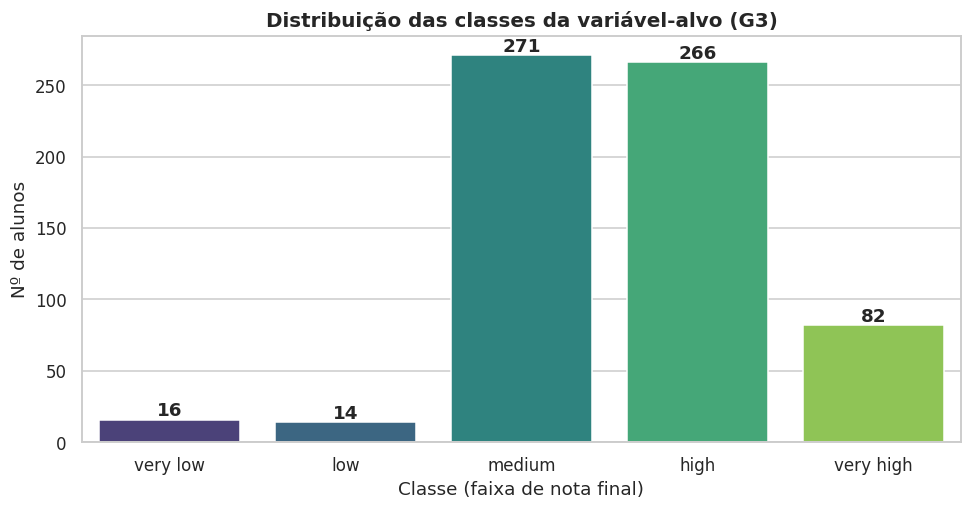

In [ ]:
# Distribuição das classes da variável-alvo
ordem_classes = ["very low", "low", "medium", "high", "very high"]
plt.figure(figsize=(9, 4.8))
ax = sns.countplot(data=df, x="G3", order=ordem_classes,
                   hue="G3", legend=False, palette="viridis")
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}", (p.get_x() + p.get_width()/2, h),
                ha="center", va="bottom", fontweight="bold")
ax.set_title("Distribuição das classes da variável-alvo (G3)")
ax.set_xlabel("Classe (faixa de nota final)"); ax.set_ylabel("Nº de alunos")
plt.tight_layout(); plt.show()

Leitura da distribuição: A base tem 649 alunos e 31 atributos (30 preditivos + a classe `G3`), atendendo aos requisitos de ≥ 500 instâncias e ≥ 30 atributos.

# Análise Univariada

As variáveis estão agrupadas por papel teórico (alvo, preditores acadêmicos, capital familiar, estilo de vida e contexto sociodemográfico) e cada uma traz a sua justificativa.

Para cada variável determinamos, conforme o tipo:
1. Distribuição (gaussiana, uniforme, exponencial/contagem...);
2. Assimetria (*skewness*);
3. Curtose (*kurtosis* — convenção de Pearson, em que 3 ≈ normal);
4. Média, desvio padrão e o significado no contexto.

Média, desvio, skewness e kurtosis só fazem sentido pleno em variáveis numéricas/ordinais. Para variáveis nominais/binárias reportamos moda e proporções e usamos gráficos de barras

In [ ]:
#Funções auxiliares

'''
Manter (skewwness e kurt) ou (classifica_assimetria e classifica_curtose)? Decisão Grupo

def skewness(df, atr):
  skewn = skew(df[atr])
  print(f'Skewness: {skewn:.2f}')
  if skewn == 0:
    print("Simétrico - Distribuição normal")
  elif skewn > 0:
    print("Assimetrico - Distribuição assimétrica positiva")
  else:
    print("Assimetrico - Distribuição assimétrica negativa")
  print()

def kurt(df, atr):
  kurto = kurtosis(df[atr], fisher = False)
  print(f'Kurtosis: {kurto:.2f}')
  if kurto == 3:
    print("Mesocurtica - Distribuição normal")
  elif kurto > 3:
    print("Leptocurtica - Cauda pesada")
  else:
    print("Platicurtica - Cauda leve")
  print()

  '''

def classifica_assimetria(sk):
    a = abs(sk)
    if a < 0.5:  return "aproximadamente simétrica"
    if a < 1.0:  return "moderadamente assimétrica"
    return "fortemente assimétrica"

def classifica_curtose(ku):  # ku = curtose de Pearson; 3 = normal
    if ku > 3.5:   return "leptocúrtica (caudas pesadas / pico acentuado)"
    if ku < 2.5:   return "platicúrtica (caudas leves / topo achatado)"
    return "mesocúrtica (próxima da normal)"

def univar_numerica(col, justificativa, tipo="numérica", bins=20):
    # Estatísticas + histograma/KDE + boxplot para variável numérica/ordinal.
    s = df[col].dropna()
    media, dp = s.mean(), s.std()
    sk = stats.skew(s); ku = stats.kurtosis(s, fisher=False)  # convenção de Pearson (normal = 3)
    print(f"───── {col}  ({tipo}) ─────")
    print(f"Justificativa: {justificativa}")
    print(f"Média = {media:.2f} | Desvio padrão = {dp:.2f} | "
          f"Mín = {s.min():.0f} | Máx = {s.max():.0f}")
    print(f"Skewness = {sk:+.2f}  →  {classifica_assimetria(sk)}")
    print(f"Kurtosis = {ku:.2f}  →  {classifica_curtose(ku)}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6),
                           gridspec_kw={"width_ratios": [3, 1]})
    sns.histplot(s, bins=bins, kde=tipo=="numérica", ax=ax[0], color="#3a7ca5")
    ax[0].axvline(media, color="#d1495b", ls="--", lw=1.5, label=f"média={media:.1f}")
    ax[0].set_title(f"Distribuição de '{col}'"); ax[0].legend()
    sns.boxplot(y=s, ax=ax[1], color="#3a7ca5")
    ax[1].set_title("Boxplot")
    plt.tight_layout(); plt.show()

def univar_categorica(col, justificativa, ordem=None):
    # Frequências + gráfico de barras para variável nominal/binária.
    s = df[col]
    freq = s.value_counts()
    prop = s.value_counts(normalize=True) * 100
    print(f"───── {col}  (categórica) ─────")
    print(f"Justificativa: {justificativa}")
    print(f"Moda = '{s.mode().iloc[0]}' | Categorias = {s.nunique()}")
    for k in freq.index:
        print(f"   {str(k):<10}: {freq[k]:>3} ({prop[k]:.1f}%)")
    plt.figure(figsize=(7, 3.6))
    sns.countplot(data=df, x=col, order=ordem if ordem else freq.index,
                  color="#3a7ca5")
    plt.title(f"Frequência de '{col}'"); plt.ylabel("Nº de alunos")
    plt.tight_layout(); plt.show()


## Grupo 1 — Variável-alvo (`G3`)

Justificativa: `G3` é a variável-alvo do trabalho — a nota final discretizada em 5 classes..

───── G3  (categórica) ─────
Justificativa: Variável-alvo: faixa da nota final (5 classes).
Moda = 'medium' | Categorias = 5
   medium    : 271 (41.8%)
   high      : 266 (41.0%)
   very high :  82 (12.6%)
   very low  :  16 (2.5%)
   low       :  14 (2.2%)


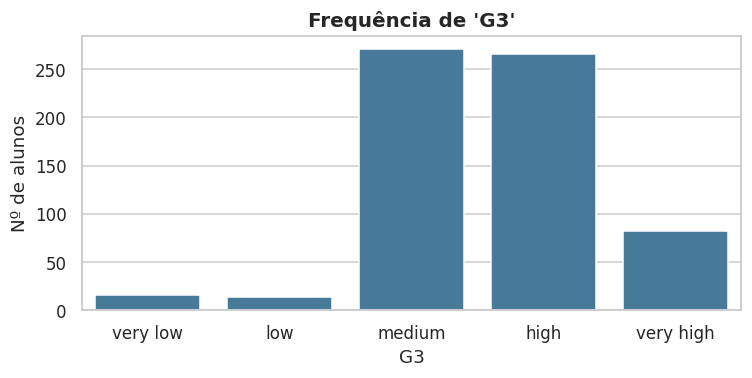

In [ ]:
univar_categorica("G3", "Variável-alvo: faixa da nota final (5 classes).",
                  ordem=["very low", "low", "medium", "high", "very high"])

Discussão: A distribuição é fortemente desbalanceada e concentrada no centro: `medium` (41,8%) e `high` (41,0%) somam ~83% dos alunos, enquanto `very low` (2,5%) e `low` (2,2%) são raras. Não é uma distribuição uniforme

## Grupo 2 — Preditores acadêmicos diretos

Justificativa: Tempo de estudo, reprovações passadas, faltas e o tempo de deslocamento são candidatos diretos a explicar o desempenho. São variáveis de altíssimo interesse para a fase preditiva.

───── studytime  (ordinal) ─────
Justificativa: Tempo semanal de estudo (1-4); preditor acadêmico.
Média = 1.93 | Desvio padrão = 0.83 | Mín = 1 | Máx = 4
Skewness = +0.70  →  moderadamente assimétrica
Kurtosis = 3.03  →  mesocúrtica (próxima da normal)


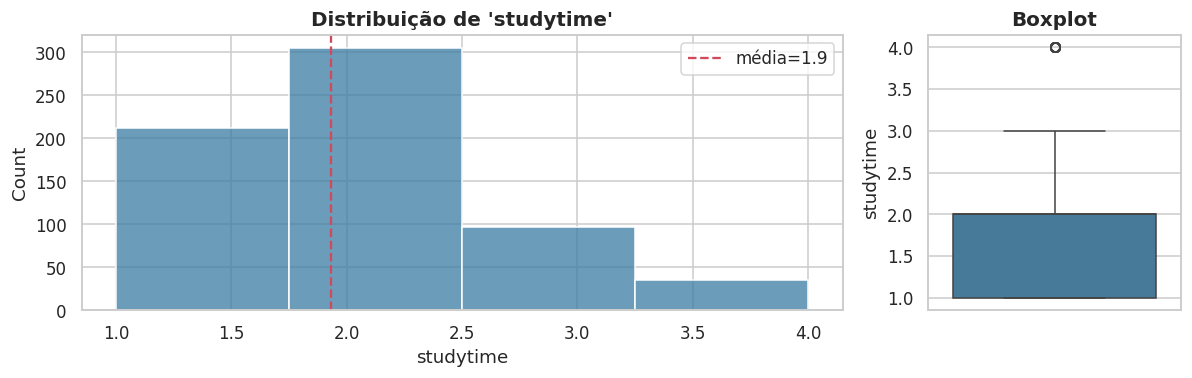

In [ ]:
univar_numerica("studytime", "Tempo semanal de estudo (1-4); preditor acadêmico.", tipo="ordinal", bins=4)

───── failures  (contagem) ─────
Justificativa: Nº de reprovações passadas (0-4); preditor de risco.
Média = 0.22 | Desvio padrão = 0.59 | Mín = 0 | Máx = 3
Skewness = +3.09  →  fortemente assimétrica
Kurtosis = 12.74  →  leptocúrtica (caudas pesadas / pico acentuado)


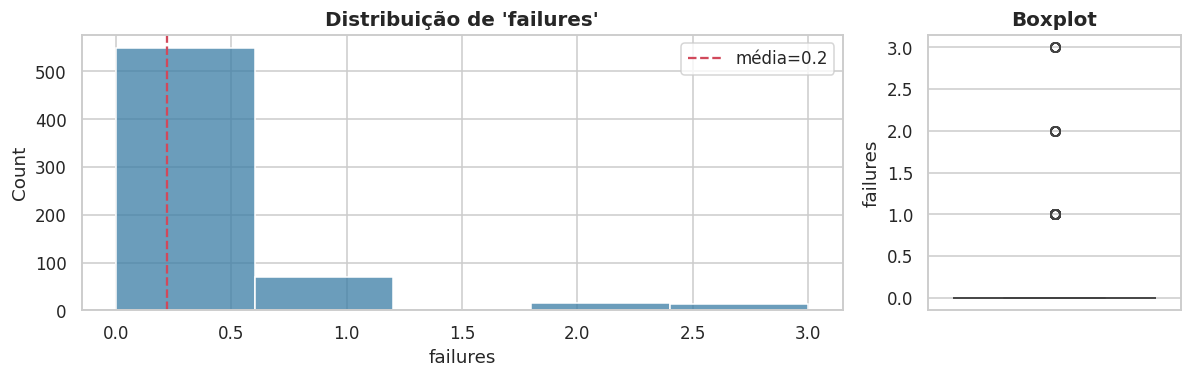

In [ ]:
univar_numerica("failures", "Nº de reprovações passadas (0-4); preditor de risco.", tipo="contagem", bins=5)

───── absences  (contagem) ─────
Justificativa: Faltas no ano (0-32); engajamento/assiduidade.
Média = 3.66 | Desvio padrão = 4.64 | Mín = 0 | Máx = 32
Skewness = +2.02  →  fortemente assimétrica
Kurtosis = 8.73  →  leptocúrtica (caudas pesadas / pico acentuado)


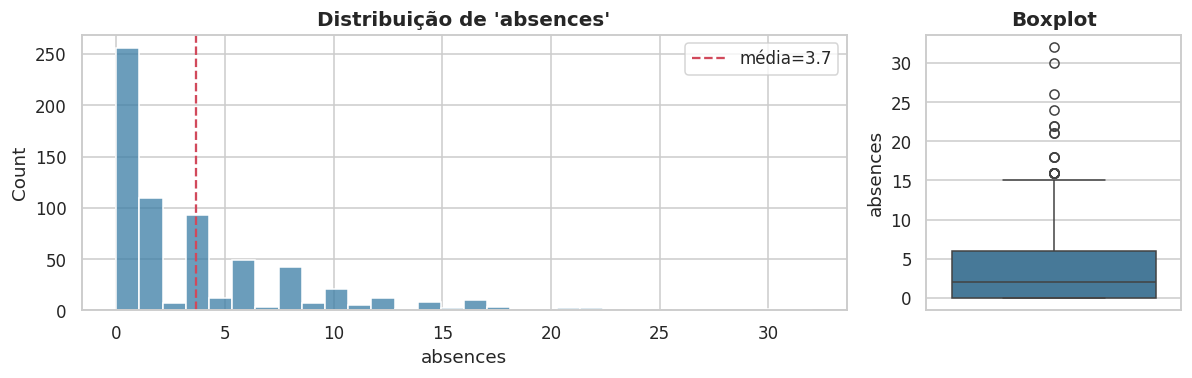

In [ ]:
univar_numerica("absences", "Faltas no ano (0-32); engajamento/assiduidade.", tipo="contagem", bins=30)

───── traveltime  (ordinal) ─────
Justificativa: Tempo de deslocamento casa-escola (1-4); logística/cansaço.
Média = 1.57 | Desvio padrão = 0.75 | Mín = 1 | Máx = 4
Skewness = +1.24  →  fortemente assimétrica
Kurtosis = 4.09  →  leptocúrtica (caudas pesadas / pico acentuado)


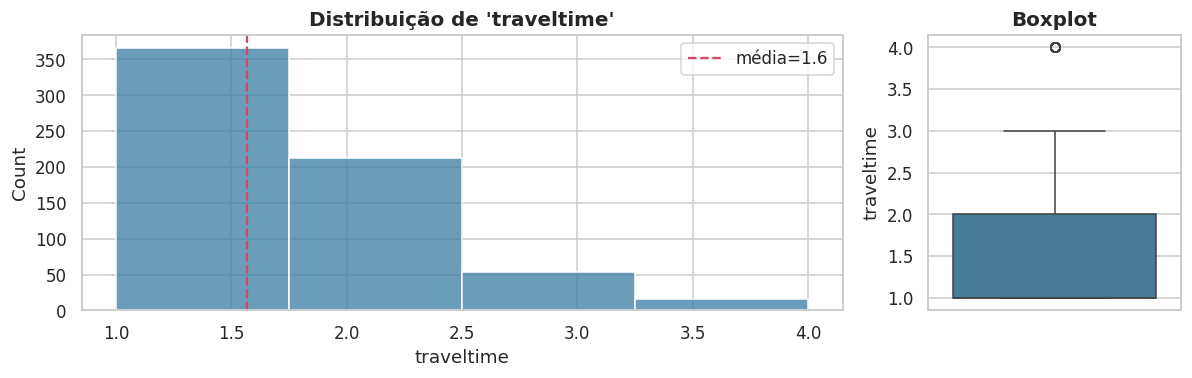

In [ ]:
univar_numerica("traveltime", "Tempo de deslocamento casa-escola (1-4); logística/cansaço.", tipo="ordinal", bins=4)

Discussão: `failures` (skew +3,09; kurtose 12,74) e `absences` (skew +2,02; kurtose 8,73) são fortemente assimétricas à direita e leptocúrticas, distribuições típicas de contagem (próximas de Poisson/exponencial), com a maioria dos alunos em zero e poucos casos extremos formando cauda longa. `traveltime` segue o mesmo padrão, porém mais brando. `studytime` é moderadamente assimétrica à direita, concentrada nos níveis 1–2 (até 5h/semana).

## Grupo 3 — Capital familiar e socioeconômico

Justificativa: escolaridade e ocupação dos pais, o responsável pelo aluno, a coabitação dos pais e o apoio familiar nos estudos são preditores socioeconômicos de desempenho escolar.

───── Medu  (ordinal) ─────
Justificativa: Escolaridade da mãe (0-4); capital cultural familiar.
Média = 2.51 | Desvio padrão = 1.13 | Mín = 0 | Máx = 4
Skewness = -0.03  →  aproximadamente simétrica
Kurtosis = 1.74  →  platicúrtica (caudas leves / topo achatado)


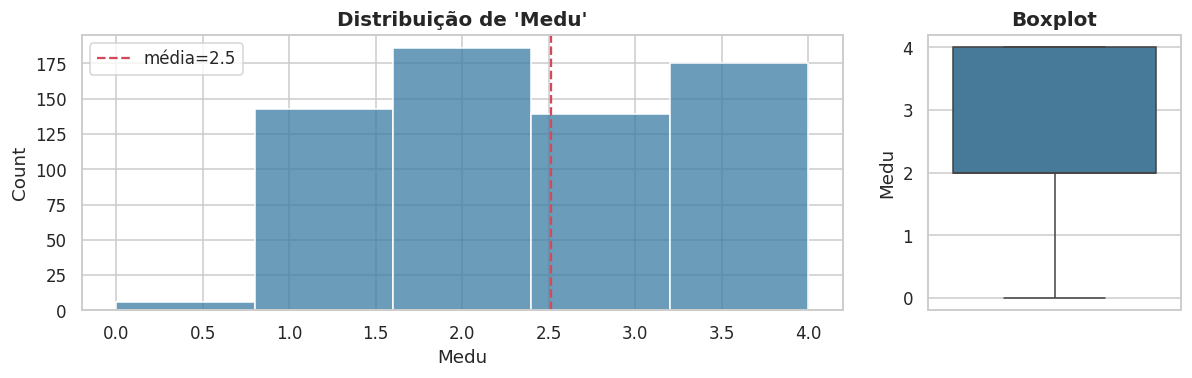

In [ ]:
univar_numerica("Medu", "Escolaridade da mãe (0-4); capital cultural familiar.", tipo="ordinal", bins=5)

───── Fedu  (ordinal) ─────
Justificativa: Escolaridade do pai (0-4); capital cultural familiar.
Média = 2.31 | Desvio padrão = 1.10 | Mín = 0 | Máx = 4
Skewness = +0.21  →  aproximadamente simétrica
Kurtosis = 1.89  →  platicúrtica (caudas leves / topo achatado)


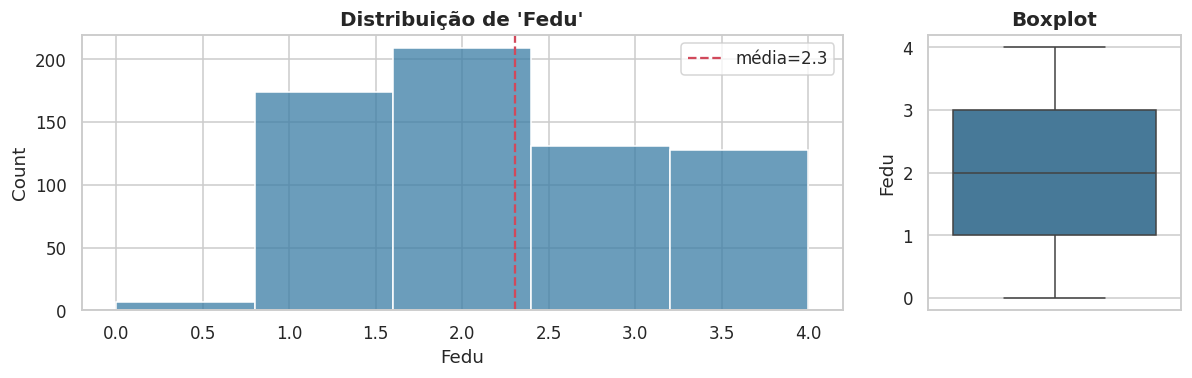

In [ ]:
univar_numerica("Fedu", "Escolaridade do pai (0-4); capital cultural familiar.", tipo="ordinal", bins=5)

───── Mjob  (categórica) ─────
Justificativa: Profissão da mãe (nominal); dimensão socioeconômica.
Moda = 'other' | Categorias = 5
   other     : 258 (39.8%)
   services  : 136 (21.0%)
   at_home   : 135 (20.8%)
   teacher   :  72 (11.1%)
   health    :  48 (7.4%)


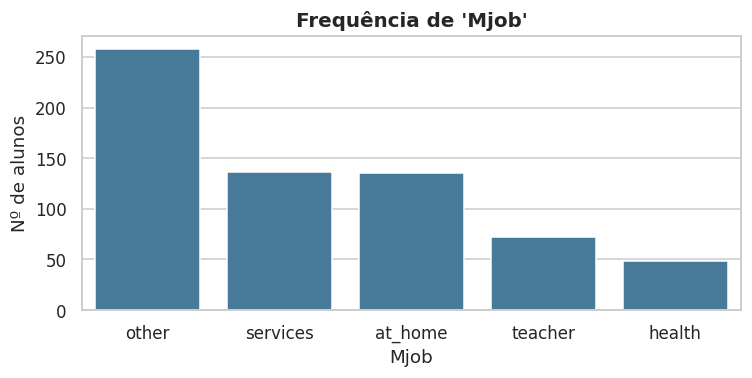

In [ ]:
univar_categorica("Mjob", "Profissão da mãe (nominal); dimensão socioeconômica.")

───── Fjob  (categórica) ─────
Justificativa: Profissão do pai (nominal); dimensão socioeconômica.
Moda = 'other' | Categorias = 5
   other     : 367 (56.5%)
   services  : 181 (27.9%)
   at_home   :  42 (6.5%)
   teacher   :  36 (5.5%)
   health    :  23 (3.5%)


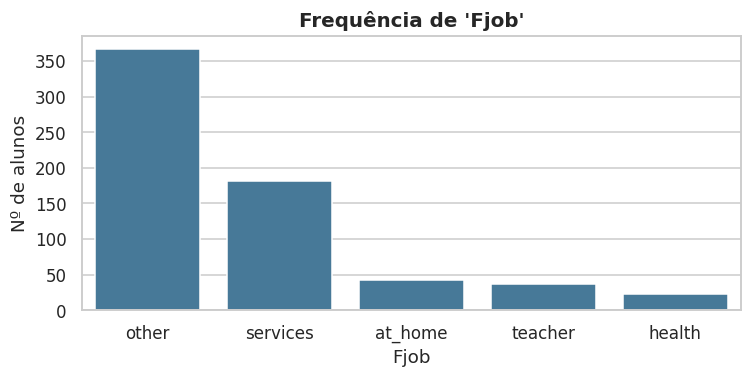

In [ ]:
univar_categorica("Fjob", "Profissão do pai (nominal); dimensão socioeconômica.")

───── guardian  (categórica) ─────
Justificativa: Responsável principal pelo aluno (nominal).
Moda = 'mother' | Categorias = 3
   mother    : 455 (70.1%)
   father    : 153 (23.6%)
   other     :  41 (6.3%)


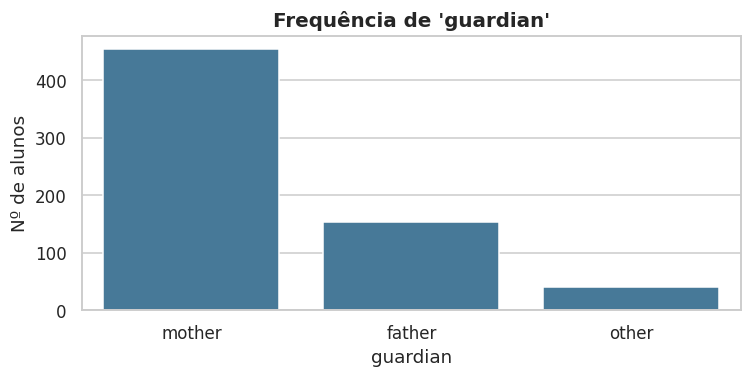

In [ ]:
univar_categorica("guardian", "Responsável principal pelo aluno (nominal).")

───── Pstatus  (categórica) ─────
Justificativa: Coabitação dos pais: juntos (T) ou separados (A).
Moda = 'T' | Categorias = 2
   T         : 569 (87.7%)
   A         :  80 (12.3%)


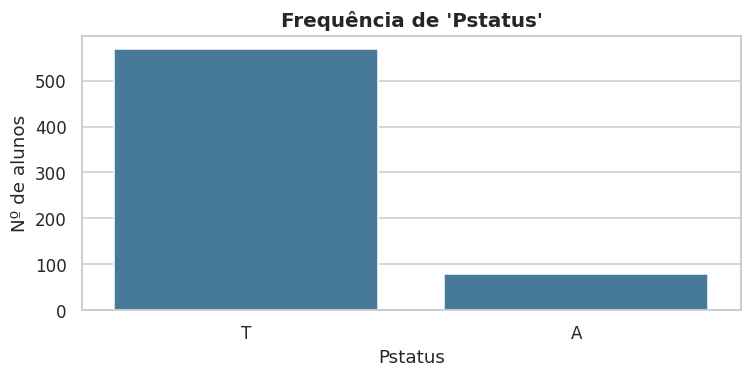

In [ ]:
univar_categorica("Pstatus", "Coabitação dos pais: juntos (T) ou separados (A).")

───── famsup  (categórica) ─────
Justificativa: Apoio educacional da família (yes/no).
Moda = 'yes' | Categorias = 2
   yes       : 398 (61.3%)
   no        : 251 (38.7%)


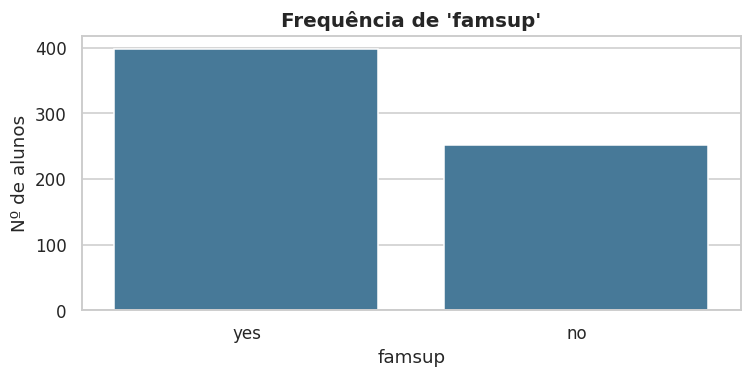

In [ ]:
univar_categorica("famsup", "Apoio educacional da família (yes/no).")

Discussão: `Medu` (skew −0,03) e `Fedu` (skew +0,21) são quase simétricas, porém platicúrticas (kurtose ≈ 1,8): a massa se espalha de forma quase uniforme pelos níveis 1–4, sem pico dominante. As profissões são dominadas por `other`, seguidas de `services`; professores e profissionais de saúde são minoria, em `Fjob` a concentração em `other` (56,5%) é ainda maior. `guardian` é majoritariamente a `mother` (70%); a maioria dos pais vive junta (`Pstatus`=T, 87,7%) e dá apoio aos estudos (`famsup`=yes, 61,3%).

## Grupo 4 — Estilo de vida e bem-estar

Justificativa: consumo de álcool, vida social, tempo livre, qualidade das relações familiares, saúde e participação em atividades extracurriculares são fatores comportamentais frequentemente associados a desempenho.

───── Walc  (ordinal) ─────
Justificativa: Consumo de álcool no fim de semana (1-5).
Média = 2.28 | Desvio padrão = 1.28 | Mín = 1 | Máx = 5
Skewness = +0.63  →  moderadamente assimétrica
Kurtosis = 2.23  →  platicúrtica (caudas leves / topo achatado)


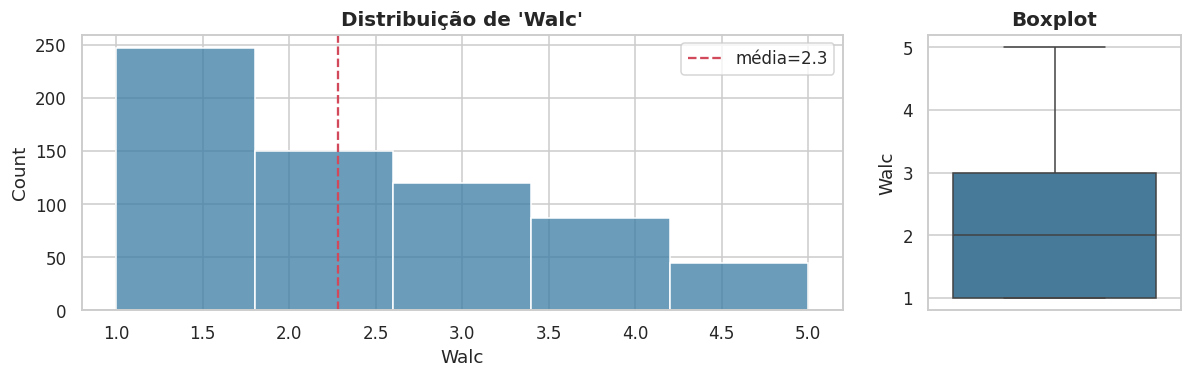

In [ ]:
univar_numerica("Walc", "Consumo de álcool no fim de semana (1-5).", tipo="ordinal", bins=5)

───── goout  (ordinal) ─────
Justificativa: Frequência de sair com amigos (1-5); vida social.
Média = 3.18 | Desvio padrão = 1.18 | Mín = 1 | Máx = 5
Skewness = -0.01  →  aproximadamente simétrica
Kurtosis = 2.13  →  platicúrtica (caudas leves / topo achatado)


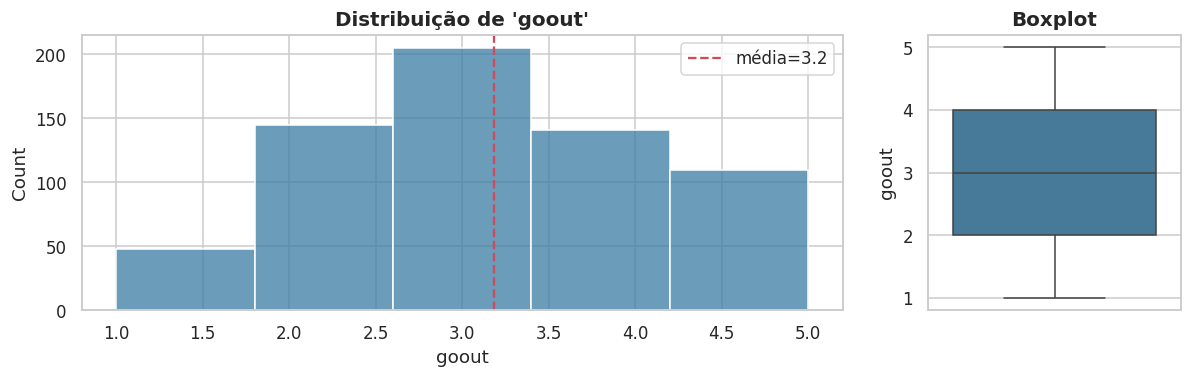

In [ ]:
univar_numerica("goout", "Frequência de sair com amigos (1-5); vida social.", tipo="ordinal", bins=5)

───── freetime  (ordinal) ─────
Justificativa: Tempo livre após a escola (1-5).
Média = 3.18 | Desvio padrão = 1.05 | Mín = 1 | Máx = 5
Skewness = -0.18  →  aproximadamente simétrica
Kurtosis = 2.60  →  mesocúrtica (próxima da normal)


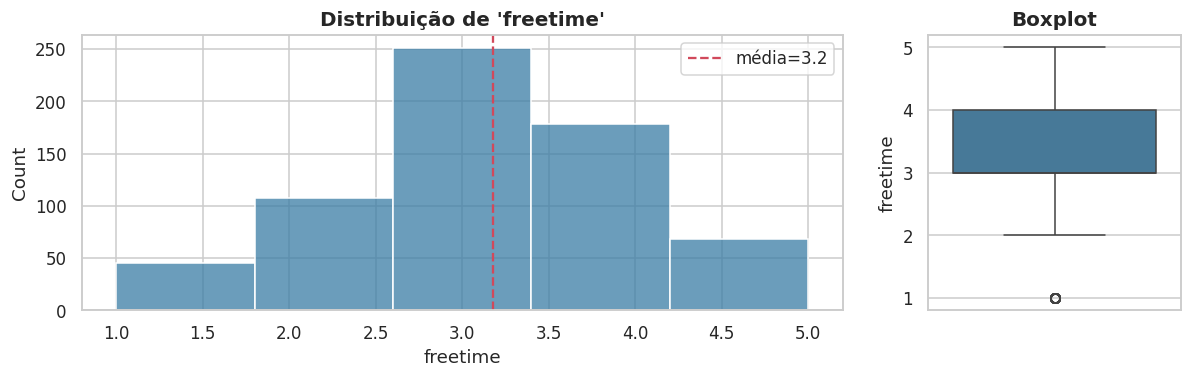

In [ ]:
univar_numerica("freetime", "Tempo livre após a escola (1-5).", tipo="ordinal", bins=5)

───── famrel  (ordinal) ─────
Justificativa: Qualidade das relações familiares (1-5).
Média = 3.93 | Desvio padrão = 0.96 | Mín = 1 | Máx = 5
Skewness = -1.10  →  fortemente assimétrica
Kurtosis = 4.33  →  leptocúrtica (caudas pesadas / pico acentuado)


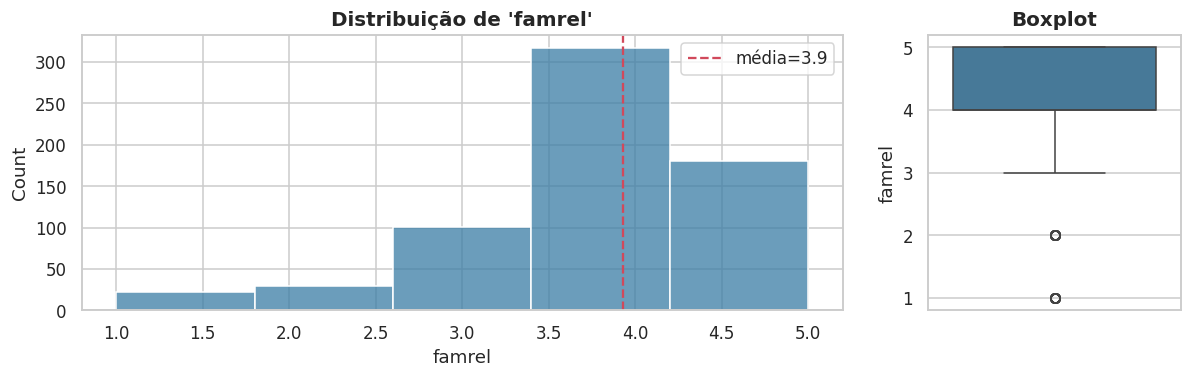

In [ ]:
univar_numerica("famrel", "Qualidade das relações familiares (1-5).", tipo="ordinal", bins=5)

───── health  (ordinal) ─────
Justificativa: Estado de saúde autodeclarado (1-5).
Média = 3.54 | Desvio padrão = 1.45 | Mín = 1 | Máx = 5
Skewness = -0.50  →  aproximadamente simétrica
Kurtosis = 1.88  →  platicúrtica (caudas leves / topo achatado)


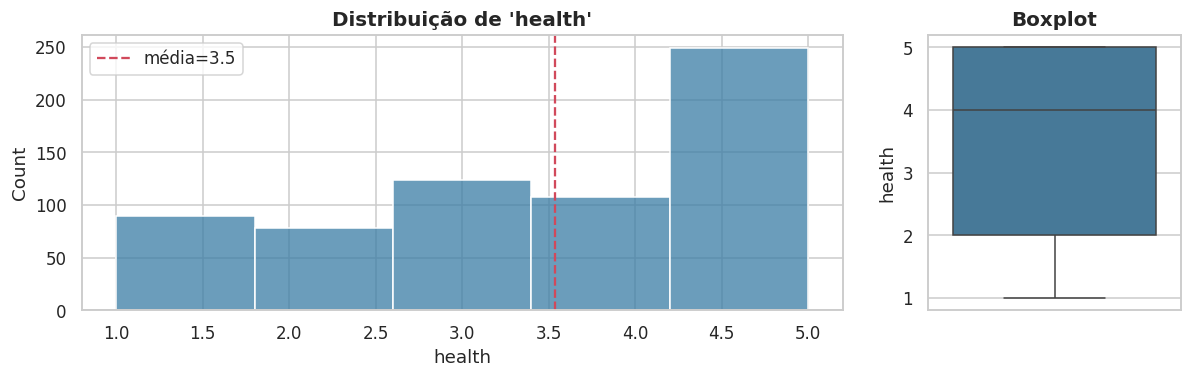

In [ ]:
univar_numerica("health", "Estado de saúde autodeclarado (1-5).", tipo="ordinal", bins=5)

───── activities  (categórica) ─────
Justificativa: Participa de atividades extracurriculares (yes/no).
Moda = 'no' | Categorias = 2
   no        : 334 (51.5%)
   yes       : 315 (48.5%)


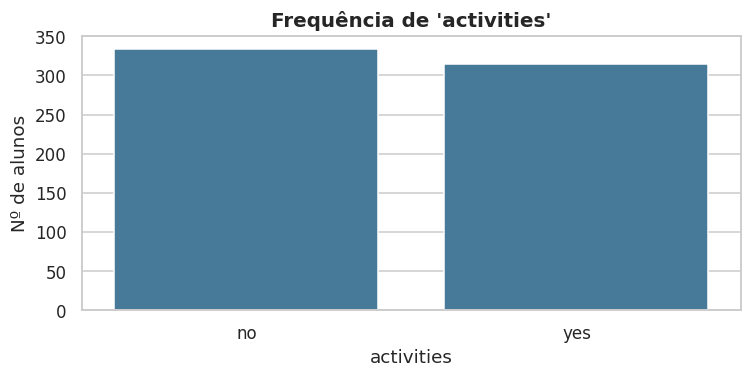

In [ ]:
univar_categorica("activities", "Participa de atividades extracurriculares (yes/no).")

Discussão: `Walc` é moderadamente assimétrica à direita (média 2,28): beber no fim de semana é comum, mas o consumo alto é minoria. `goout` (skew −0,01) e `freetime` (skew −0,18) são quase simétricas em torno de 3. `famrel` (skew −1,10) e `health` (skew −0,50) são assimétricas à esquerda, concentradas nos níveis altos (boas relações, boa saúde). `activities` está praticamente dividida ao meio (48,5% sim).

## Grupo 5 — Contexto sociodemográfico e escolar

Justificativa: variáveis que permitem segmentar a população e testar diferenças entre grupos (idade, sexo, zona de moradia, aspiração ao ensino superior, acesso à internet, apoio escolar extra, relacionamento e histórico pré-escolar).

───── age  (numérica) ─────
Justificativa: Idade (15-22 anos); contexto etário.
Média = 16.74 | Desvio padrão = 1.22 | Mín = 15 | Máx = 22
Skewness = +0.42  →  aproximadamente simétrica
Kurtosis = 3.06  →  mesocúrtica (próxima da normal)


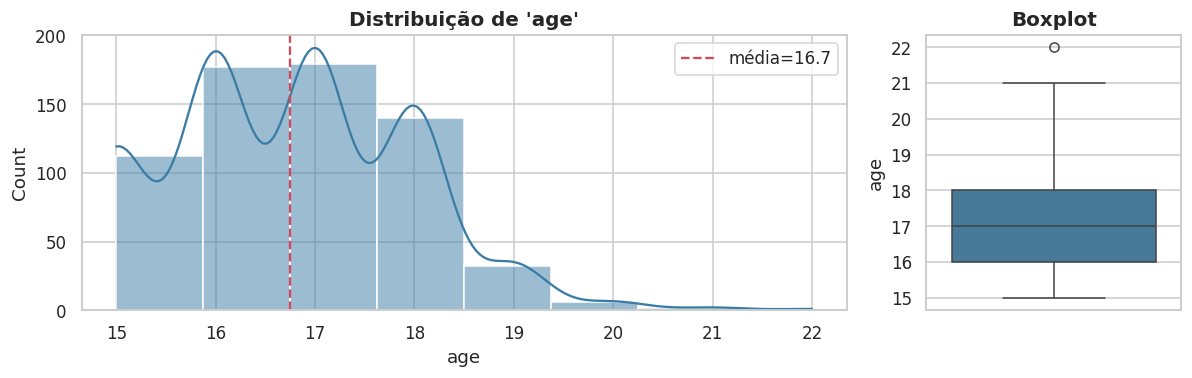

In [ ]:
univar_numerica("age", "Idade (15-22 anos); contexto etário.", tipo="numérica", bins=8)

───── sex  (categórica) ─────
Justificativa: Sexo do aluno (F/M); segmentação demográfica básica.
Moda = 'F' | Categorias = 2
   F         : 383 (59.0%)
   M         : 266 (41.0%)


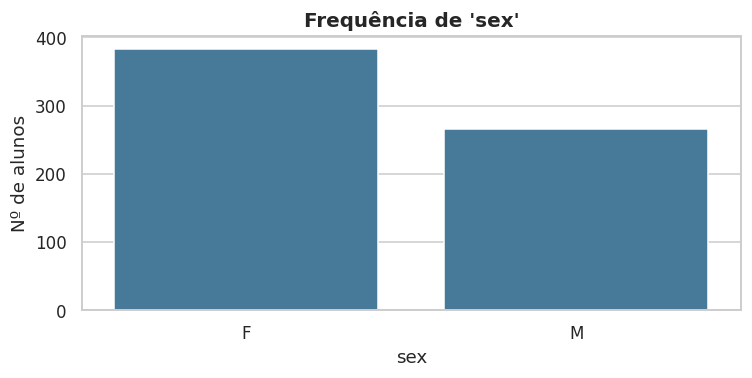

In [ ]:
univar_categorica("sex", "Sexo do aluno (F/M); segmentação demográfica básica.")

───── address  (categórica) ─────
Justificativa: Zona de moradia (Urbana/Rural).
Moda = 'U' | Categorias = 2
   U         : 452 (69.6%)
   R         : 197 (30.4%)


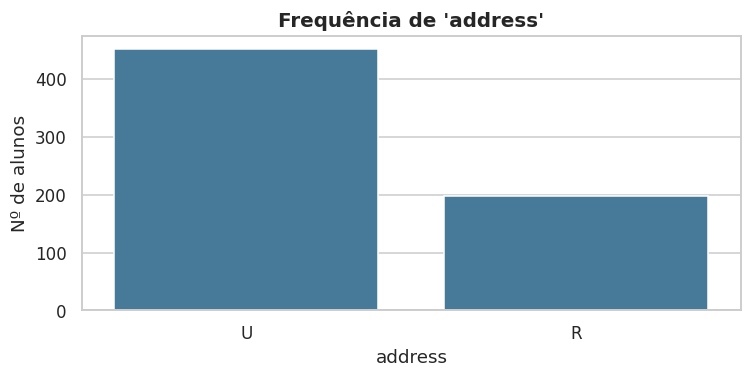

In [ ]:
univar_categorica("address", "Zona de moradia (Urbana/Rural).")

───── higher  (categórica) ─────
Justificativa: Pretende cursar ensino superior (yes/no); proxy de aspiração.
Moda = 'yes' | Categorias = 2
   yes       : 580 (89.4%)
   no        :  69 (10.6%)


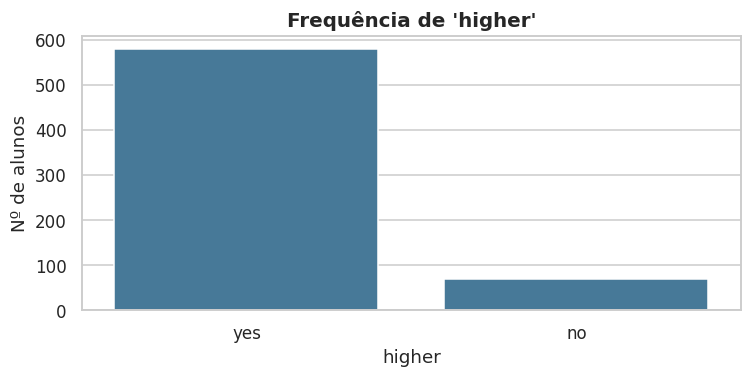

In [ ]:
univar_categorica("higher", "Pretende cursar ensino superior (yes/no); proxy de aspiração.")

───── internet  (categórica) ─────
Justificativa: Acesso à internet em casa (yes/no).
Moda = 'yes' | Categorias = 2
   yes       : 498 (76.7%)
   no        : 151 (23.3%)


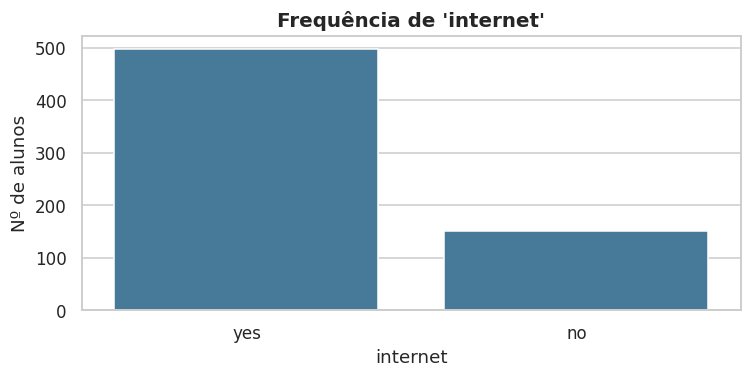

In [ ]:
univar_categorica("internet", "Acesso à internet em casa (yes/no).")

───── schoolsup  (categórica) ─────
Justificativa: Apoio educacional extra da escola (yes/no).
Moda = 'no' | Categorias = 2
   no        : 581 (89.5%)
   yes       :  68 (10.5%)


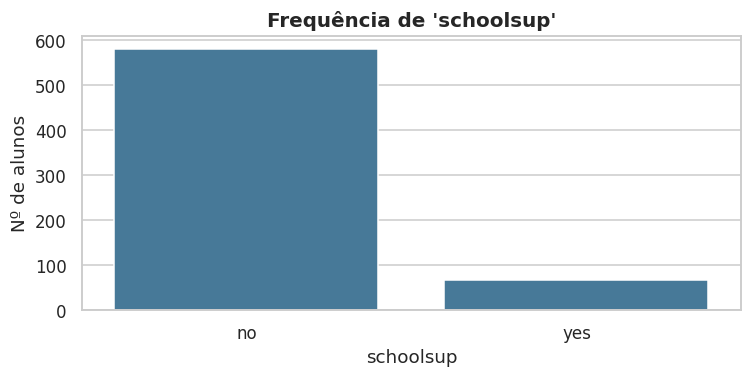

In [ ]:
univar_categorica("schoolsup", "Apoio educacional extra da escola (yes/no).")

───── romantic  (categórica) ─────
Justificativa: Está em relacionamento amoroso (yes/no).
Moda = 'no' | Categorias = 2
   no        : 410 (63.2%)
   yes       : 239 (36.8%)


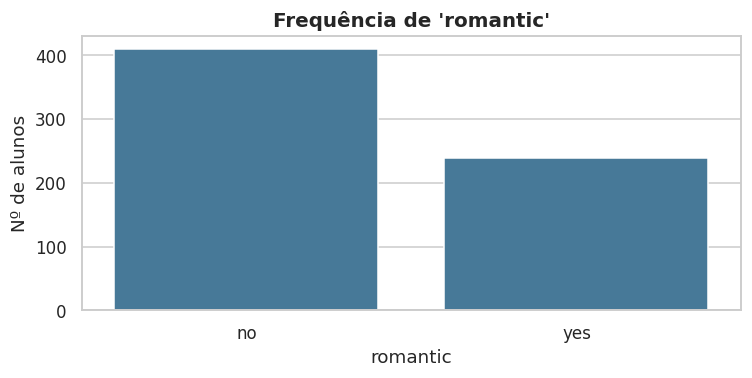

In [ ]:
univar_categorica("romantic", "Está em relacionamento amoroso (yes/no).")

───── nursery  (categórica) ─────
Justificativa: Frequentou creche/pré-escola (yes/no).
Moda = 'yes' | Categorias = 2
   yes       : 521 (80.3%)
   no        : 128 (19.7%)


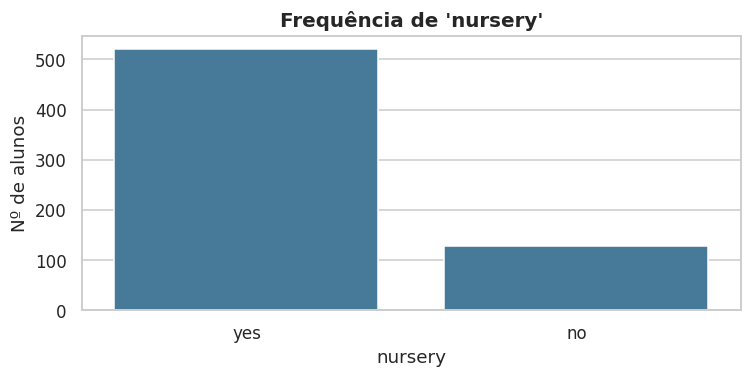

In [ ]:
univar_categorica("nursery", "Frequentou creche/pré-escola (yes/no).")

Discussão: `age` é moderadamente assimétrica à direita (skew +0,42), concentrada em 15–18 anos com poucos alunos mais velhos (até 22), formando uma cauda direita. As binárias mostram uma população predominantemente feminina (59%), urbana (69,6%), com alta aspiração ao ensino superior (89,4% `higher`=yes), boa cobertura de internet (76,7%) e histórico de pré-escola (80,3%). O apoio escolar extra é raro (`schoolsup`=yes apenas 10,5%) e ~37% estão em relacionamento.

# Análise Multivariada

<b>Hipótese:</b> Existe uma relação positiva entre o tempo de estudo (<code>studytime</code>) e a nota final (<code>G3</code>): alunos que estudam mais tendem a obter notas finais mais altas.

Foi utilizado um <i>heatmap</i>, pois ambas as variáveis são categóricas e ele facilita visualizar a frequência com que cada faixa de nota aparece dentro de cada nível de tempo de estudo.

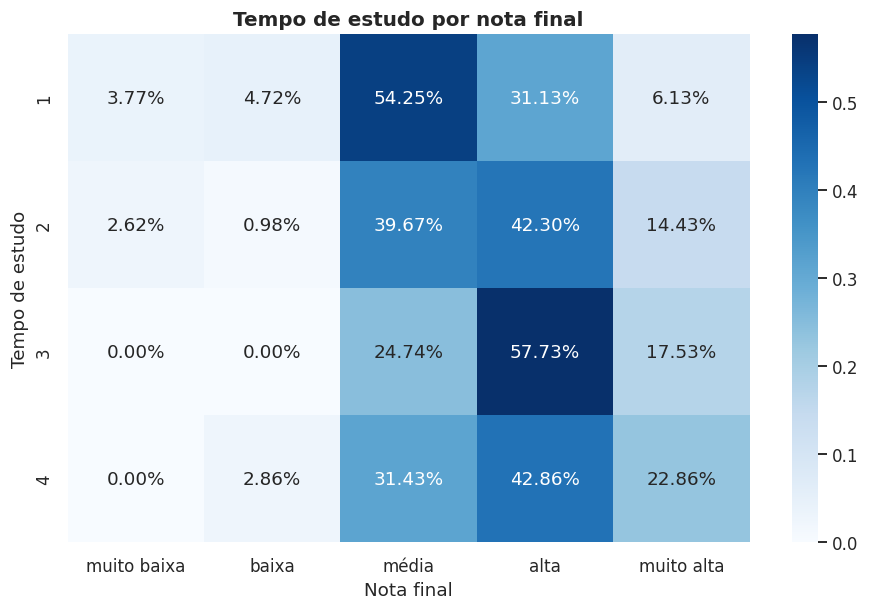

In [ ]:
studytime_g3_ct = pd.crosstab(df['studytime'], df['G3'], normalize='index')
studytime_g3_ct.columns = ['muito baixa', 'baixa', 'média', 'alta', 'muito alta']

plt.figure(figsize=(10, 6))
sns.heatmap(studytime_g3_ct, annot=True, cmap='Blues', fmt='.2%')
plt.title('Tempo de estudo por nota final')
plt.xlabel('Nota final')
plt.ylabel('Tempo de estudo')
plt.show()

<b>Conclusão:</b> A hipótese se confirma. Conforme o tempo de estudo aumenta, a massa de alunos se desloca para as faixas <code>alta</code> e <code>muito alta</code>: entre os que estudam de 5 a 10 horas por semana (nível 3), 57,7% ficam em <code>alta</code> e 17,5% em <code>muito alta</code>, sem nenhum aluno nas faixas mais baixas. O nível 4 (>10h) mantém o padrão de notas altas.

<b>Hipótese:</b> Alunos com maior tempo de deslocamento até a escola (<code>traveltime</code>) tendem a apresentar maior número de faltas (<code>absences</code>).

Foi utilizado um gráfico de barras com a <b>média bruta de faltas</b> por nível de deslocamento, com o eixo Y começando em zero, para comparar honestamente a magnitude das diferenças sem distorções de escala.

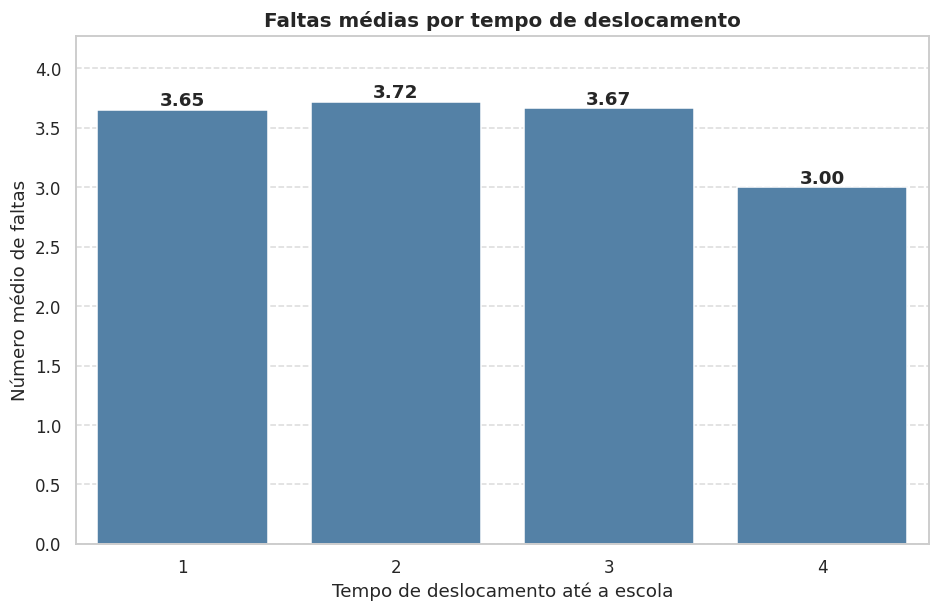

In [ ]:
mean_absences_tt = df.groupby('traveltime')['absences'].mean().reset_index()

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='traveltime', y='absences', data=mean_absences_tt, color='steelblue')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontweight='bold')
plt.title('Faltas médias por tempo de deslocamento')
plt.xlabel('Tempo de deslocamento até a escola')
plt.ylabel('Número médio de faltas')
plt.ylim(0, mean_absences_tt['absences'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

<b>Conclusão:</b> A hipótese não se confirma. As médias de faltas por nível de deslocamento são praticamente iguais (3,65 / 3,72 / 3,67 / 3,00) e, na verdade, o grupo que mais demora (>1h) é o que <b>menos</b> falta. As diferenças são pequenas e não indicam relação entre tempo de deslocamento e assiduidade.

<b>Hipótese:</b> Alunos com pior condição de saúde (<code>health</code>) tendem a apresentar um número maior de faltas (<code>absences</code>).

Foi utilizado um gráfico de barras (eixo Y começando em zero) para comparar a média de faltas em cada nível de saúde sem sugerir uma tendência contínua que não existe.

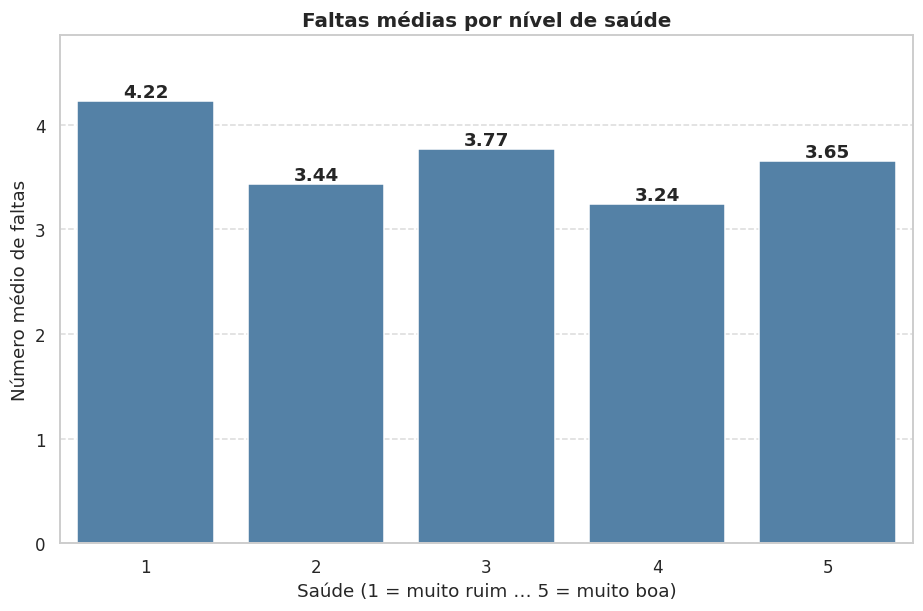

In [ ]:
mean_absences_h = df.groupby('health')['absences'].mean().reset_index()

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='health', y='absences', data=mean_absences_h, color='steelblue')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontweight='bold')
plt.title('Faltas médias por nível de saúde')
plt.xlabel('Saúde (1 = muito ruim … 5 = muito boa)')
plt.ylabel('Número médio de faltas')
plt.ylim(0, mean_absences_h['absences'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

<b>Conclusão:</b> A hipótese se sustenta apenas parcialmente. A relação <b>não é monotônica</b>: as médias de faltas por nível de saúde (1→5) são 4,22 / 3,44 / 3,77 / 3,24 / 3,65. Apenas o nível 1 (pior saúde) se destaca com mais faltas; entre os níveis 2 e 5 a variação é pequena e sem tendência clara. Ou seja, saúde muito ruim parece elevar as faltas, mas não há um gradiente consistente de "pior saúde → mais faltas".

<b>Hipótese:</b> Alunos cujos pais possuem maior nível de escolaridade (<code>Medu</code> e <code>Fedu</code>) tendem a obter notas finais (<code>G3</code>) mais altas.

Foi utilizado um gráfico de pontos com a <b>média</b> da escolaridade dos pais e o intervalo de confiança de 95% por faixa de nota, o que evidencia a tendência de forma mais limpa do que um boxplot (a média de <code>Medu</code>/<code>Fedu</code> assume poucos valores discretos).

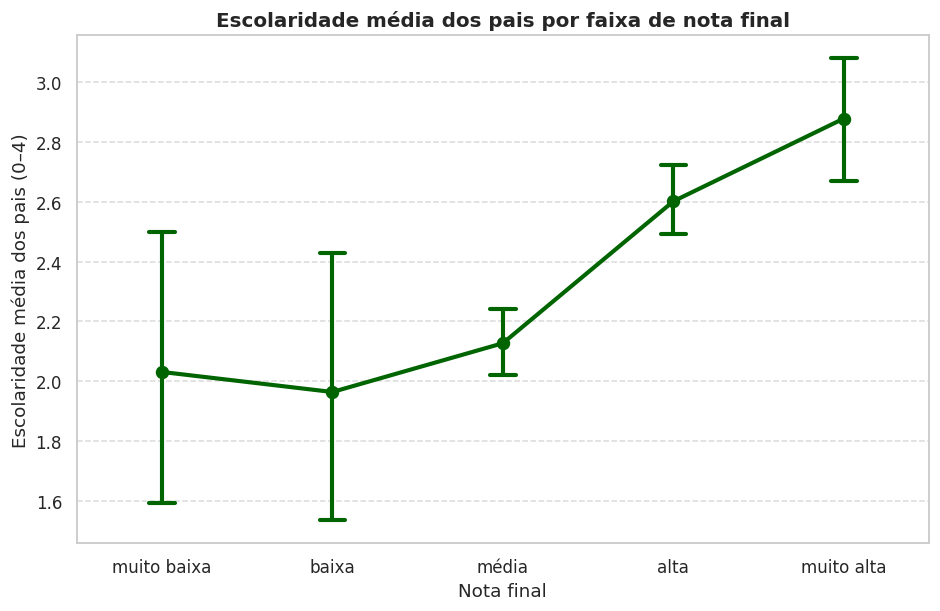

In [ ]:
df['parent_edu_avg'] = df[['Medu', 'Fedu']].mean(axis=1)
ordem = ['very low', 'low', 'medium', 'high', 'very high']
rotulos = ['muito baixa', 'baixa', 'média', 'alta', 'muito alta']

plt.figure(figsize=(10, 6))
ax = sns.pointplot(x='G3', y='parent_edu_avg', data=df, order=ordem,
                   errorbar=('ci', 95), color='darkgreen', capsize=.15)
ax.set_xticks(range(len(rotulos)))
ax.set_xticklabels(rotulos)
plt.title('Escolaridade média dos pais por faixa de nota final')
plt.xlabel('Nota final')
plt.ylabel('Escolaridade média dos pais (0–4)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

<b>Conclusão:</b> A hipótese se confirma. A escolaridade média dos pais cresce de forma consistente nas faixas mais altas: fica em torno de 2,0 nas faixas <code>muito baixa</code>/<code>baixa</code>/<code>média</code> e sobe para 2,60 (<code>alta</code>) e 2,88 (<code>muito alta</code>). Os intervalos de confiança das faixas altas não se sobrepõem aos das baixas, indicando que a diferença é consistente: alunos com notas mais altas tendem a vir de famílias com maior escolaridade.

<b>Hipótese:</b> Alunos que recebem apoio escolar (<code>schoolsup</code>) e familiar (<code>famsup</code>) tendem a obter notas finais (<code>G3</code>) mais altas do que aqueles que não recebem nenhum tipo de suporte.

Foi utilizado um gráfico de barras 100% empilhadas, que mostra a distribuição das faixas de nota dentro de cada combinação de apoio — uma visão normalizada que não é distorcida pelo desbalanceamento das classes.

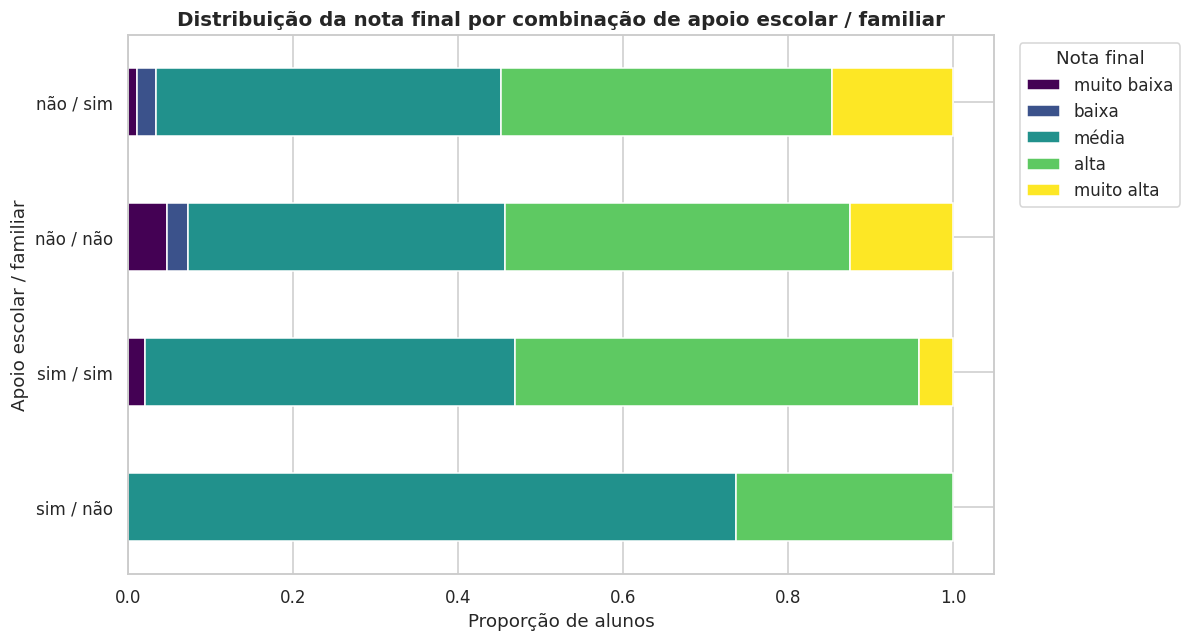

In [ ]:
ordem = ['very low', 'low', 'medium', 'high', 'very high']
rotulos = ['muito baixa', 'baixa', 'média', 'alta', 'muito alta']
map_sn = {'yes': 'sim', 'no': 'não'}
df['sf_support'] = df['schoolsup'].map(map_sn) + ' / ' + df['famsup'].map(map_sn)

ordem_combo = ['sim / não', 'sim / sim', 'não / não', 'não / sim']
sf_ct = pd.crosstab(df['sf_support'], df['G3'], normalize='index')[ordem].reindex(ordem_combo)
sf_ct.columns = rotulos

ax = sf_ct.plot(kind='barh', stacked=True, figsize=(11, 6), colormap='viridis')
plt.title('Distribuição da nota final por combinação de apoio escolar / familiar')
plt.xlabel('Proporção de alunos')
plt.ylabel('Apoio escolar / familiar')
plt.legend(title='Nota final', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

<b>Conclusão (achado não óbvio):</b> A hipótese <b>não se confirma</b>, e o padrão é o oposto do esperado. Os alunos que recebem apoio escolar (<code>schoolsup</code> = sim) têm proporção <b>menor</b> de notas altas: a combinação "sim / não" tem apenas 26,3% em <code>alta</code>/<code>muito alta</code>, contra ~54% nos grupos sem apoio escolar. A explicação mais provável é causalidade reversa: o reforço escolar é oferecido justamente a quem já tem dificuldade, então a variável sinaliza alunos em risco, não causa boas notas. Já o apoio familiar (<code>famsup</code>) praticamente não altera a distribuição (54,7% com apoio vs 54,3% sem). Ressalva: os grupos com apoio escolar são pequenos (a combinação "sim / não" tem só 19 alunos).

<b>Hipótese:</b> Alunos com maior tempo de estudo (<code>studytime</code>), melhor saúde (<code>health</code>), menos faltas (<code>absences</code>), menos reprovações (<code>failures</code>), menor tempo de deslocamento (<code>traveltime</code>) e menor consumo de álcool no fim de semana (<code>Walc</code>) tendem a obter notas finais (<code>G3</code>) mais altas.

A análise foi feita com <b>PCA</b>, que projeta as seis variáveis numéricas em dois componentes principais, facilitando visualizar grupos e padrões em um único gráfico.

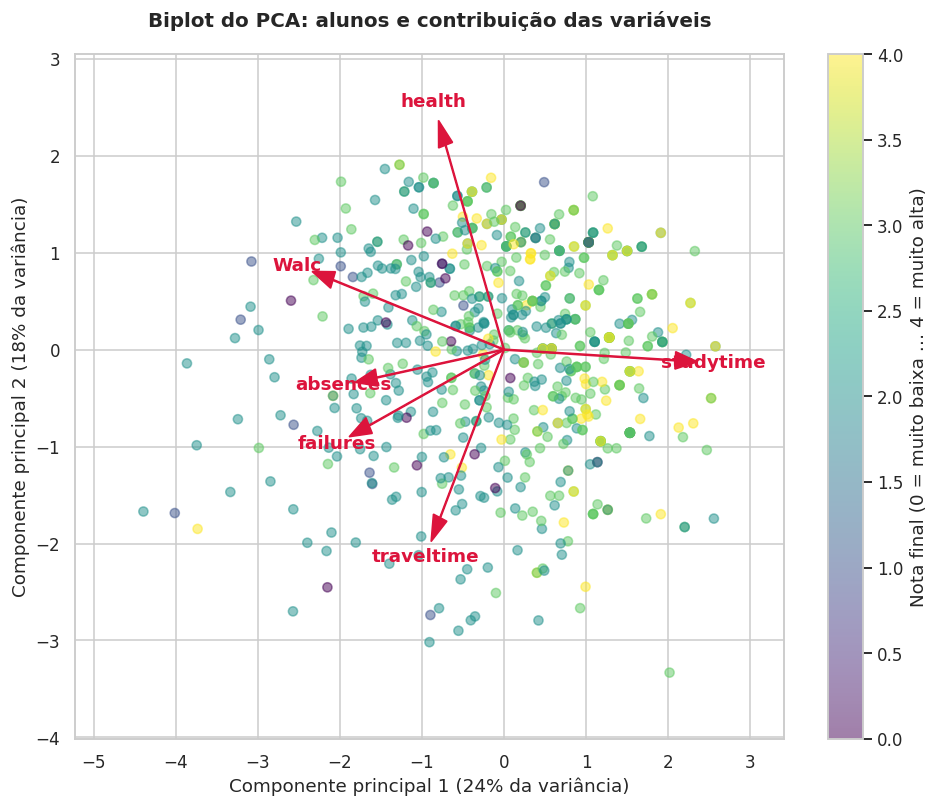

              PC1    PC2
studytime   0.536 -0.038
failures   -0.429 -0.270
absences   -0.413 -0.101
traveltime -0.202 -0.594
Walc       -0.532  0.242
health     -0.182  0.710


In [ ]:
numeric_cols = ['studytime', 'failures', 'absences', 'traveltime', 'Walc', 'health']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[numeric_cols])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(9, 7.5))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.5, c=df['G3'].cat.codes, cmap='viridis')

# Setas dos loadings (biplot), escaladas para a nuvem de pontos
load = pca.components_.T
esc = np.abs(X_pca).max(axis=0)
for k, var in enumerate(numeric_cols):
    ax.arrow(0, 0, load[k, 0] * esc[0], load[k, 1] * esc[1],
             color='crimson', width=0.01, head_width=0.18, length_includes_head=True, zorder=5)
    ax.text(load[k, 0] * esc[0] * 1.08, load[k, 1] * esc[1] * 1.08, var,
            color='crimson', fontweight='bold', ha='center', va='center', zorder=6)

ax.margins(0.12)
ax.set_title('Biplot do PCA: alunos e contribuição das variáveis', pad=18)
ax.set_xlabel(f'Componente principal 1 ({pca.explained_variance_ratio_[0]*100:.0f}% da variância)')
ax.set_ylabel(f'Componente principal 2 ({pca.explained_variance_ratio_[1]*100:.0f}% da variância)')
fig.colorbar(sc, label='Nota final (0 = muito baixa … 4 = muito alta)')
plt.tight_layout()
plt.show()

# Tabela de loadings das duas primeiras componentes
loadings = pd.DataFrame(pca.components_.T,
    columns=['PC1', 'PC2'], index=numeric_cols)
print(loadings.round(3))

<b>Conclusão:</b> A hipótese se sustenta na direção geral. As setas do biplot mostram que <code>studytime</code> aponta para a direita (PC1 positivo), enquanto <code>failures</code>, <code>Walc</code> e <code>absences</code> apontam para o lado oposto, e as notas mais altas (cores claras) concentram-se justamente à direita, onde esses fatores de risco são baixos e o tempo de estudo é alto. No eixo vertical, <code>health</code> e <code>traveltime</code> puxam em sentidos contrários. Ressalva importante: as duas primeiras componentes explicam pouca variância total, então o PCA dá uma visão geral das tendências, mas não separa os alunos em grupos nítidos por nota.

<b>Hipótese:</b> Alunos com mais reprovações passadas (<code>failures</code>) tendem a obter notas finais (<code>G3</code>) mais baixas.

Foi utilizado um gráfico de barras 100% empilhadas, que mostra como a composição das faixas de nota muda conforme o número de reprovações.

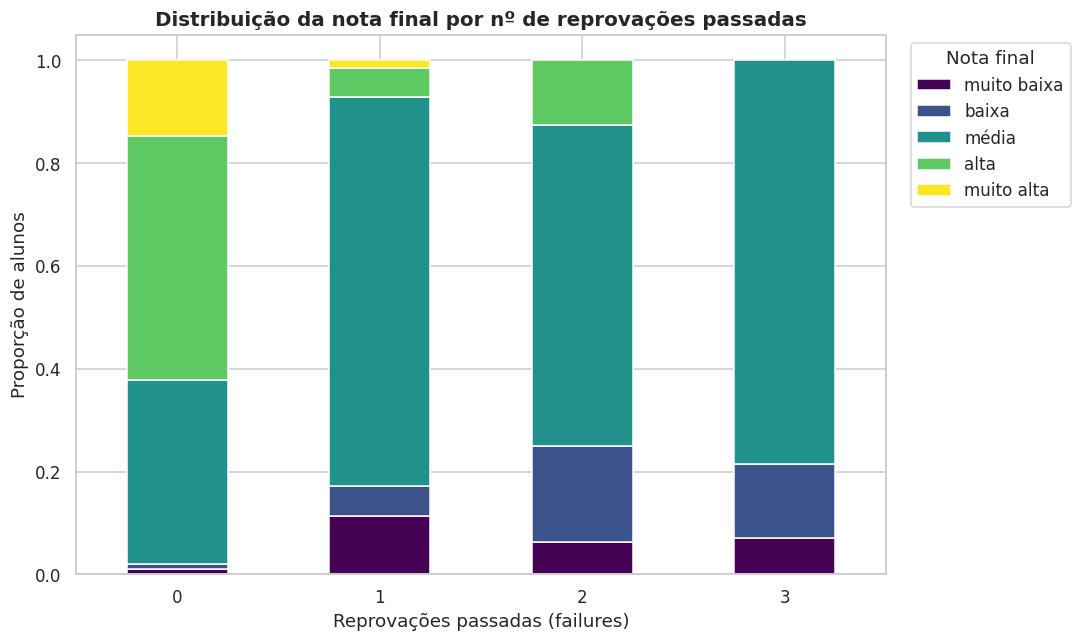

In [ ]:
ordem = ['very low', 'low', 'medium', 'high', 'very high']
rotulos = ['muito baixa', 'baixa', 'média', 'alta', 'muito alta']

fail_ct = pd.crosstab(df['failures'], df['G3'], normalize='index')[ordem]
fail_ct.columns = rotulos

ax = fail_ct.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Distribuição da nota final por nº de reprovações passadas')
plt.xlabel('Reprovações passadas (failures)')
plt.ylabel('Proporção de alunos')
plt.xticks(rotation=0)
plt.legend(title='Nota final', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

<b>Conclusão:</b> Hipótese <b>confirmada e forte</b>. Entre os alunos sem reprovações, 62% estão em <code>alta</code>/<code>muito alta</code>; com apenas 1 reprovação isso despenca para 7%, e com 3 reprovações nenhum aluno atinge as faixas altas. <code>failures</code> é o preditor individual mais forte da nota (correlação de Spearman de −0,41).

<b>Hipótese:</b> Alunos que pretendem cursar o ensino superior (<code>higher</code>) tendem a obter notas finais (<code>G3</code>) mais altas.

Foi utilizado um gráfico de barras comparando o percentual de alunos em nota alta/muito alta entre quem pretende e quem não pretende cursar o ensino superior.

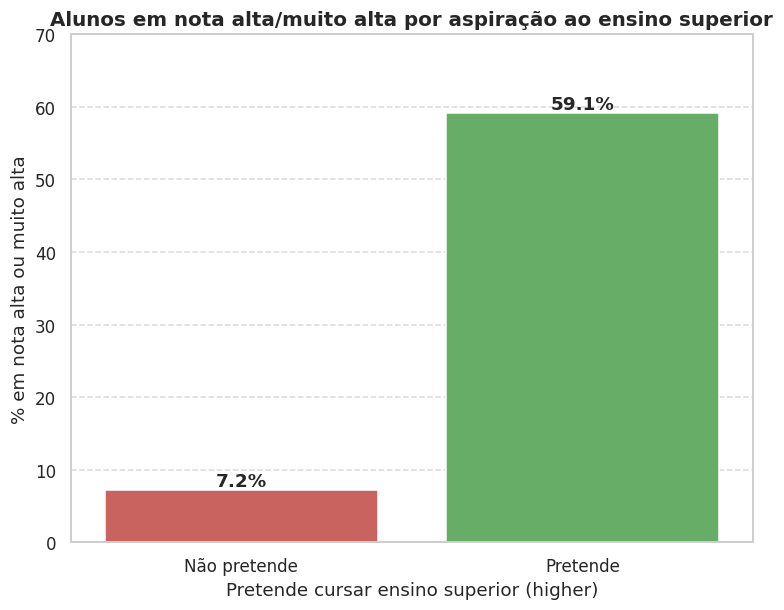

In [ ]:
ordem_altas = ['high', 'very high']
higher_ct = pd.crosstab(df['higher'], df['G3'], normalize='index')
pct_altas = (higher_ct[ordem_altas].sum(axis=1) * 100).reindex(['no', 'yes'])

plt.figure(figsize=(8, 6))
ax = sns.barplot(x=pct_altas.index, y=pct_altas.values, hue=pct_altas.index,
                 palette=['#d9534f', '#5cb85c'], legend=False)
for i, v in enumerate(pct_altas.values):
    ax.annotate(f"{v:.1f}%", (i, v), ha='center', va='bottom', fontweight='bold')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Não pretende', 'Pretende'])
plt.title('Alunos em nota alta/muito alta por aspiração ao ensino superior')
plt.xlabel('Pretende cursar ensino superior (higher)')
plt.ylabel('% em nota alta ou muito alta')
plt.ylim(0, 70)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

<b>Conclusão:</b> Hipótese <b>confirmada, com efeito enorme</b>. 59,1% dos alunos que pretendem cursar o ensino superior estão em nota alta/muito alta, contra apenas 7,2% dos que não pretendem, a diferença mais nítida entre todas as variáveis categóricas analisadas. Vale a ressalva de que a base é desbalanceada (580 "sim" contra 69 "não"), o que torna o grupo "não" pequeno.

<b>Hipótese:</b> As variáveis acadêmicas (<code>studytime</code>, <code>failures</code>) e de capital familiar (<code>Medu</code>, <code>Fedu</code>) têm correlação mais forte com a nota final do que as variáveis de estilo de vida (<code>Walc</code>, <code>goout</code>, <code>freetime</code>, <code>health</code>).

Foi utilizado um mapa de calor com as correlações de Spearman entre todas as variáveis numéricas/ordinais (técnica além das vistas em aula), que dá uma visão geral das relações de uma só vez. A nota final é representada por <code>g3_num</code> (codificação ordinal de 0 a 4 das faixas de <code>G3</code>).

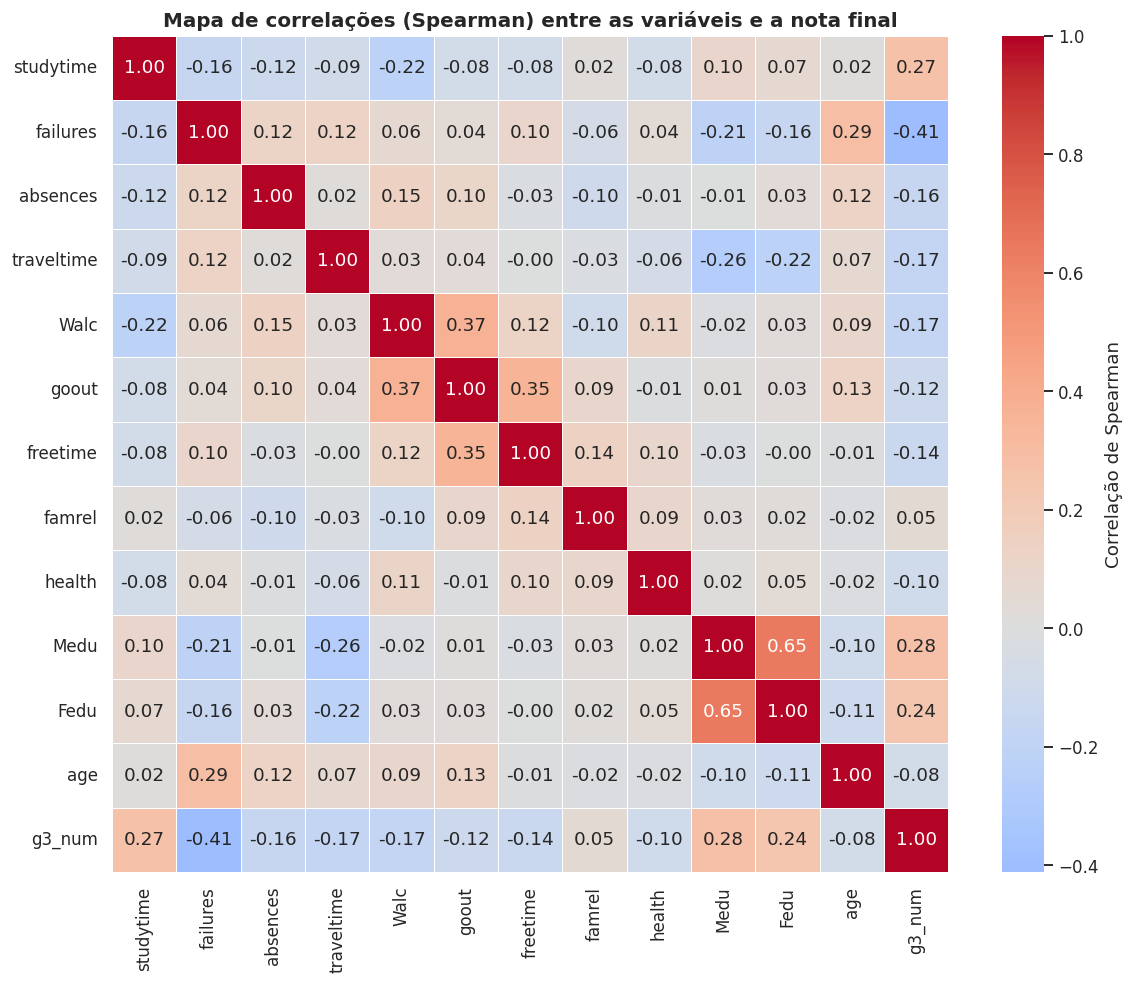

In [ ]:
df['g3_num'] = df['G3'].cat.codes

cols_corr = ['studytime', 'failures', 'absences', 'traveltime', 'Walc', 'goout',
             'freetime', 'famrel', 'health', 'Medu', 'Fedu', 'age', 'g3_num']
corr = df[cols_corr].corr(method='spearman')

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=.5, cbar_kws={'label': 'Correlação de Spearman'})
plt.title('Mapa de correlações (Spearman) entre as variáveis e a nota final')
plt.tight_layout()
plt.show()

<b>Conclusão:</b> Hipótese <b>confirmada</b>. Sobre a nota (<code>g3_num</code>), os maiores pesos positivos são <code>Medu</code> (+0,28), <code>studytime</code> (+0,27) e <code>Fedu</code> (+0,24), e o maior peso negativo é <code>failures</code> (−0,41). As variáveis de estilo de vida têm correlações fracas (<code>Walc</code> −0,17, <code>freetime</code> −0,14, <code>goout</code> −0,12, <code>health</code> −0,10). O mapa ainda revela duas relações entre preditores: <code>Medu</code> e <code>Fedu</code> são fortemente correlacionadas entre si, e <code>goout</code>↔<code>Walc</code> (+0,37) formam um eixo de sociabilidade.

<b>Hipótese:</b> Alunos com mais faltas (<code>absences</code>) tendem a obter notas finais (<code>G3</code>) mais baixas.

As faltas foram agrupadas em faixas e o gráfico de barras mostra a faixa média da nota (codificada de 0 = muito baixa a 4 = muito alta) em cada faixa de faltas.

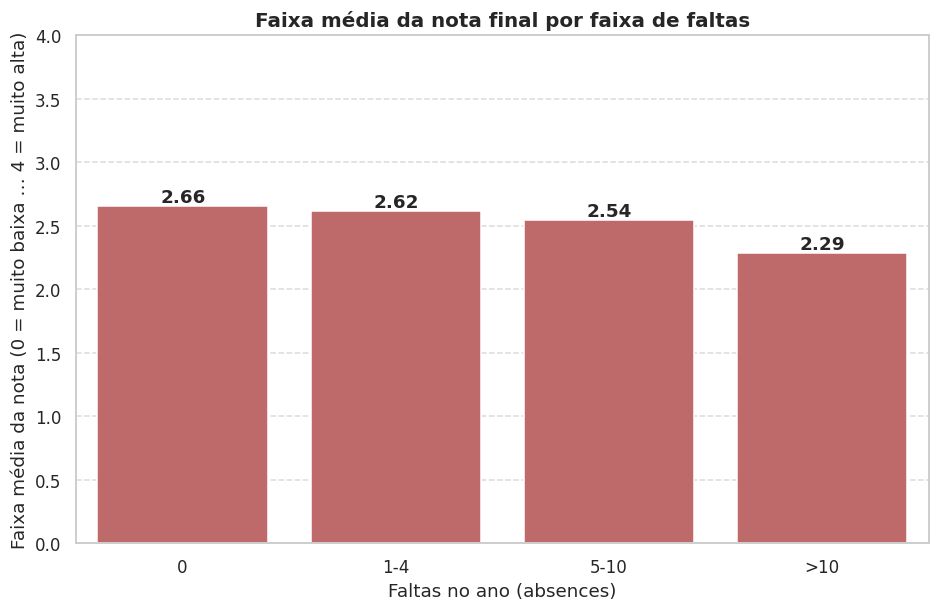

In [ ]:
df['g3_num'] = df['G3'].cat.codes
df['abs_faixa'] = pd.cut(df['absences'], [-1, 0, 4, 10, 100],
                         labels=['0', '1-4', '5-10', '>10'])
media_abs = df.groupby('abs_faixa', observed=True)['g3_num'].mean().reset_index()

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='abs_faixa', y='g3_num', data=media_abs, color='indianred')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontweight='bold')
plt.title('Faixa média da nota final por faixa de faltas')
plt.xlabel('Faltas no ano (absences)')
plt.ylabel('Faixa média da nota (0 = muito baixa … 4 = muito alta)')
plt.ylim(0, 4)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

<b>Conclusão (achado não óbvio):</b> O efeito é <b>surpreendentemente fraco</b>. A faixa média da nota cai apenas de 2,66 (zero faltas) para 2,29 (>10 faltas), numa escala de 0 a 4, e a maioria dos alunos permanece em <code>média</code>/<code>alta</code> independentemente das faltas. Diferentemente de <code>failures</code> (efeito forte), faltar muito quase não muda a faixa de nota — provavelmente porque a avaliação em Português combina trabalhos e provas que faltas pontuais não comprometem. A correlação de Spearman é de apenas −0,16.

# Gráficos Finais (Visualização Eficaz de Dados)

Nesta seção aprimoramos **5 visualizações da análise multivariada** para um público leigo

In [ ]:
COR_DESTAQUE = '#2c7fb8'
COR_NEUTRA   = '#c9d3da'
COR_ALERTA   = '#e6712f'

def estilo_limpo(ax, titulo, subtitulo=''):
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    ax.set_title(titulo, fontsize=13.5, fontweight='bold', loc='left',
                 pad=24 if subtitulo else 12)
    if subtitulo:
        ax.text(0, 1.03, subtitulo, transform=ax.transAxes, fontsize=10,
                color='#555555', ha='left', va='bottom')

### Gráfico Final 1 — Reprovações anteriores (a partir da análise de `failures`)

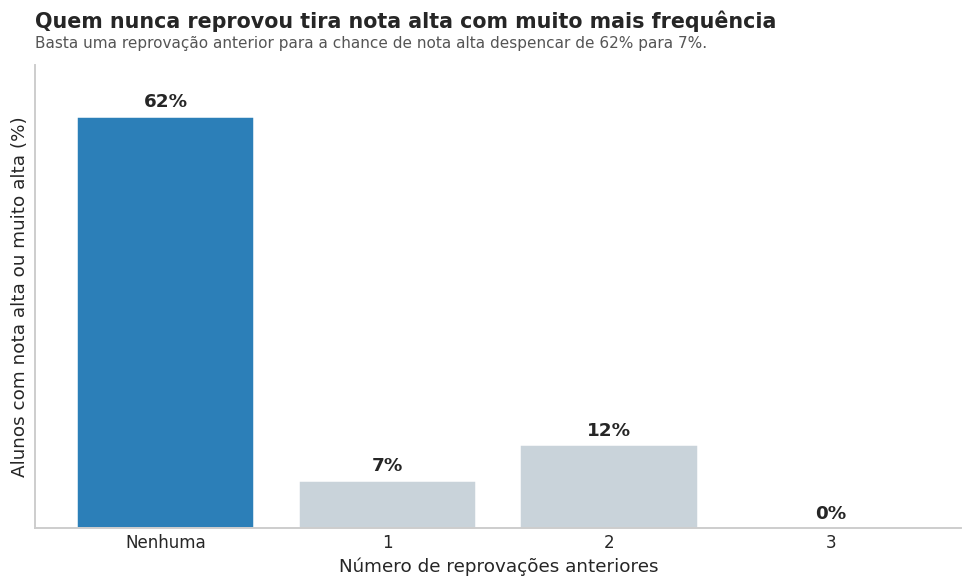

In [ ]:
serie = (pd.crosstab(df['failures'], df['G3'], normalize='index')[['high', 'very high']]
         .sum(axis=1) * 100).reindex([0, 1, 2, 3])
labels = ['Nenhuma', '1', '2', '3']
cores = [COR_DESTAQUE, COR_NEUTRA, COR_NEUTRA, COR_NEUTRA]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(labels, serie.values, color=cores)
for b, v in zip(bars, serie.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
ax.set_ylim(0, 70); ax.set_yticks([])
ax.set_xlabel('Número de reprovações anteriores')
ax.set_ylabel('Alunos com nota alta ou muito alta (%)')
estilo_limpo(ax, 'Quem nunca reprovou tira nota alta com muito mais frequência',
             'Basta uma reprovação anterior para a chance de nota alta despencar de 62% para 7%.')
plt.tight_layout(); plt.show()

**Leitura.** A chance de chegar a uma nota alta cai de **62%** (nenhuma reprovação) para **7%** logo na primeira reprovação. Reprovações anteriores são o sinal de alerta mais forte da base.

### Gráfico Final 2 — Aspiração ao ensino superior (a partir de `higher`)

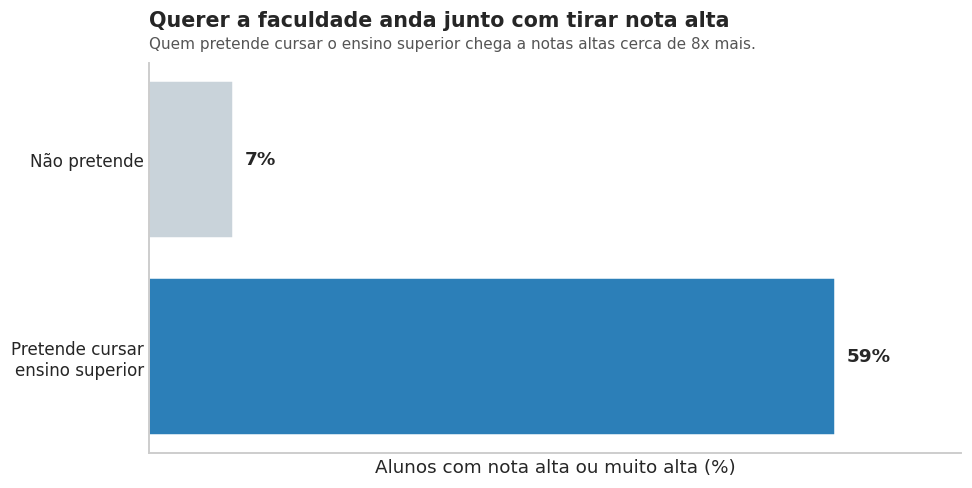

In [ ]:
serie = (pd.crosstab(df['higher'], df['G3'], normalize='index')[['high', 'very high']]
         .sum(axis=1) * 100).reindex(['no', 'yes'])
labels = ['Não pretende', 'Pretende cursar\nensino superior']
cores = [COR_NEUTRA, COR_DESTAQUE]

fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.barh(labels, serie.values, color=cores)
for b, v in zip(bars, serie.values):
    ax.text(v + 1, b.get_y() + b.get_height()/2, f'{v:.0f}%', va='center', fontweight='bold')
ax.set_xlim(0, 70); ax.set_xticks([])
ax.set_xlabel('Alunos com nota alta ou muito alta (%)')
ax.invert_yaxis()
estilo_limpo(ax, 'Querer a faculdade anda junto com tirar nota alta',
             'Quem pretende cursar o ensino superior chega a notas altas cerca de 8x mais.')
plt.tight_layout(); plt.show()

**Leitura.** **59%** dos alunos que pretendem cursar o ensino superior tiram nota alta, contra apenas **7%** dos que não pretendem.

### Gráfico Final 3 — Tempo de estudo (a partir de `studytime`)

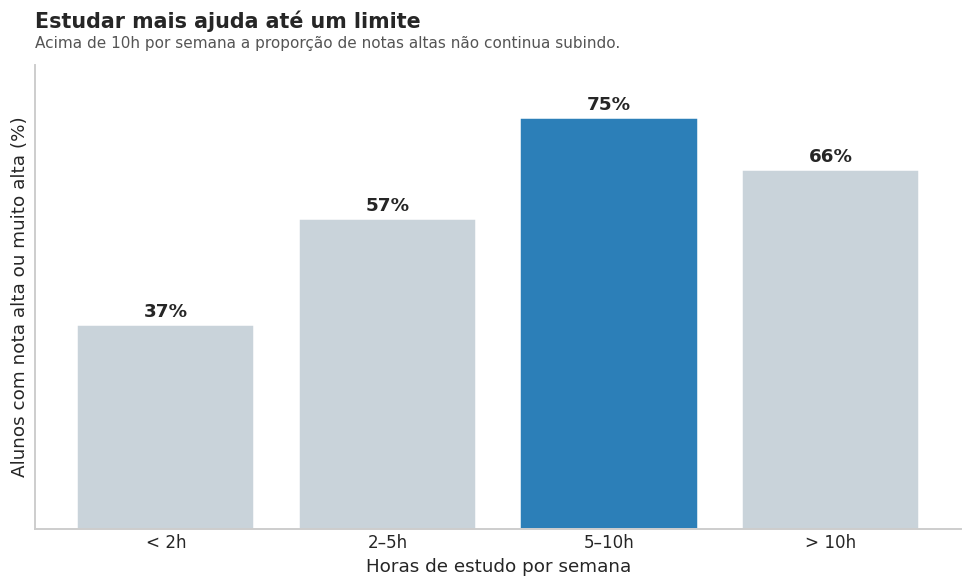

In [ ]:
serie = (pd.crosstab(df['studytime'], df['G3'], normalize='index')[['high', 'very high']]
         .sum(axis=1) * 100).reindex([1, 2, 3, 4])
labels = ['< 2h', '2–5h', '5–10h', '> 10h']
cores = [COR_NEUTRA, COR_NEUTRA, COR_DESTAQUE, COR_NEUTRA]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(labels, serie.values, color=cores)
for b, v in zip(bars, serie.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
ax.set_ylim(0, 85); ax.set_yticks([])
ax.set_xlabel('Horas de estudo por semana')
ax.set_ylabel('Alunos com nota alta ou muito alta (%)')
estilo_limpo(ax, 'Estudar mais ajuda até um limite',
             'Acima de 10h por semana a proporção de notas altas não continua subindo.')
plt.tight_layout(); plt.show()

**Leitura.** A proporção de notas altas sobe de **37%** (menos de 2h) para **75%** (5–10h), mas **estaciona** acima de 10h. Mais estudo ajuda até um ponto de saturação.

### Gráfico Final 4 — Escolaridade dos pais (a partir de `Medu`/`Fedu`)

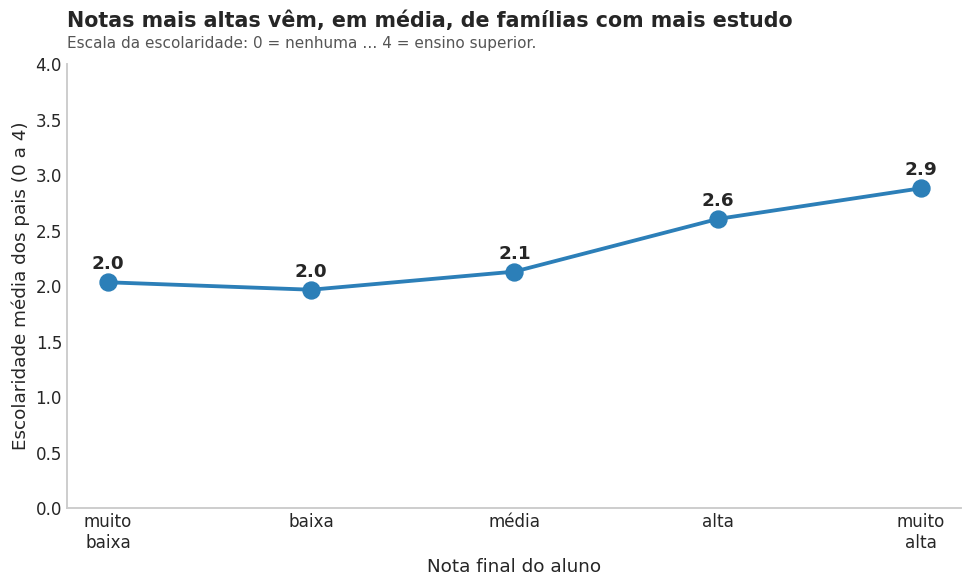

In [ ]:
ordem = ['very low', 'low', 'medium', 'high', 'very high']
rot = ['muito\nbaixa', 'baixa', 'média', 'alta', 'muito\nalta']
df['parent_edu_avg'] = df[['Medu', 'Fedu']].mean(axis=1)
med = df.groupby('G3', observed=True)['parent_edu_avg'].mean().reindex(ordem)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(range(5), med.values, marker='o', markersize=11, color=COR_DESTAQUE, linewidth=2.5)
for i, v in enumerate(med.values):
    ax.text(i, v + 0.12, f'{v:.1f}', ha='center', fontweight='bold')
ax.set_xticks(range(5)); ax.set_xticklabels(rot)
ax.set_ylim(0, 4)
ax.set_ylabel('Escolaridade média dos pais (0 a 4)')
ax.set_xlabel('Nota final do aluno')
estilo_limpo(ax, 'Notas mais altas vêm, em média, de famílias com mais estudo',
             'Escala da escolaridade: 0 = nenhuma … 4 = ensino superior.')
plt.tight_layout(); plt.show()

**Leitura.** A escolaridade média dos pais sobe de **2,0** nas faixas mais baixas para **2,9** na faixa mais alta. É uma tendência consistente, ainda que mais suave do que os outros fatores.

### Gráfico Final 5 — Reforço escolar (a partir de `schoolsup`)

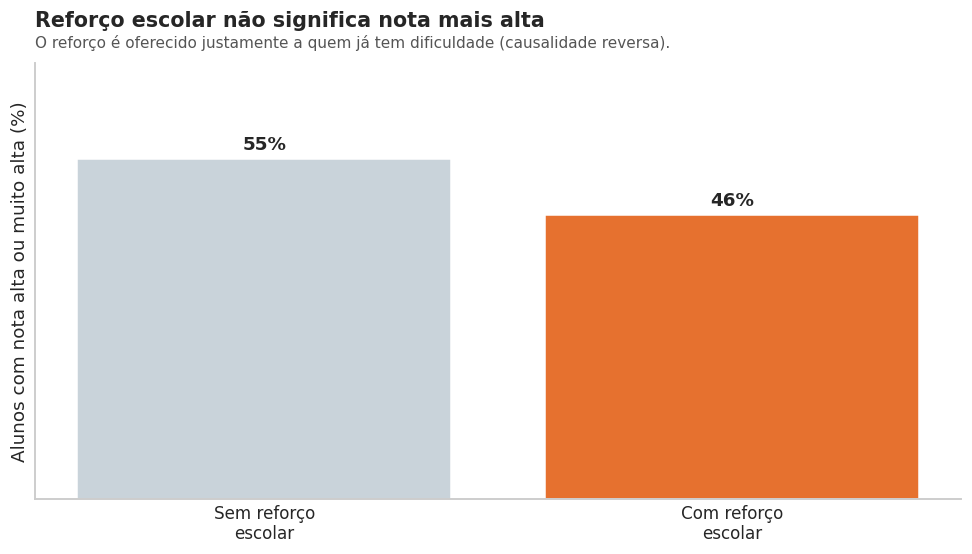

In [ ]:
serie = (pd.crosstab(df['schoolsup'], df['G3'], normalize='index')[['high', 'very high']]
         .sum(axis=1) * 100).reindex(['no', 'yes'])
labels = ['Sem reforço\nescolar', 'Com reforço\nescolar']
cores = [COR_NEUTRA, COR_ALERTA]

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.bar(labels, serie.values, color=cores)
for b, v in zip(bars, serie.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
ax.set_ylim(0, 70); ax.set_yticks([])
ax.set_ylabel('Alunos com nota alta ou muito alta (%)')
estilo_limpo(ax, 'Reforço escolar não significa nota mais alta',
             'O reforço é oferecido justamente a quem já tem dificuldade (causalidade reversa).')
plt.tight_layout(); plt.show()

**Leitura.** Alunos **com** reforço escolar tiram nota alta um pouco **menos** (46%) do que os sem reforço (55%). O reforço não causa nota baixa, ele apenas sinaliza alunos que já precisavam de ajuda.

# Pipeline

In [ ]:
# crie nesta seção o pipeline com as etapas de pré-processamento necessárias

binary_cols = [
    "school", "sex", "address", "famsize", "Pstatus",
    "schoolsup", "famsup", "paid", "activities",
    "nursery", "higher", "internet", "romantic",
]

nominal_cols = ["Mjob", "Fjob", "reason", "guardian"]

numeric_cols = [
    "age", "Medu", "Fedu", "traveltime", "studytime",
    "failures", "famrel", "freetime", "goout",
    "Dalc", "Walc", "health", "absences",
]

X = df.drop(columns=["G3"])
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Treino : {X_train.shape[0]} instâncias")
print(f"Teste  : {X_test.shape[0]} instâncias")

# ─── ColumnTransformer ────────────────────────────────────────────────────────
preprocessor = ColumnTransformer(
    transformers=[
        # 1) Binárias → 0/1 via OrdinalEncoder
        (
            "bin",
            OrdinalEncoder(dtype=float),
            binary_cols,
        ),
        # 2) Nominais → dummies via OneHotEncoder
        (
            "ohe",
            OneHotEncoder(drop="first", sparse_output=False, dtype=float),
            nominal_cols,
        ),
        # 3) Numéricas/ordinais → StandardScaler
        (
            "std",
            StandardScaler(),
            numeric_cols,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# ─── Pipeline ────────────────────────────────────────────────────────
pipeline_std = Pipeline(steps=[("prep", preprocessor)])

X_train_prep = pipeline_std.fit_transform(X_train)
X_test_prep  = pipeline_std.transform(X_test)

print(f"\nShape treino pré-processado : {X_train_prep.shape}")
print(f"Shape teste  pré-processado : {X_test_prep.shape}")

# MinMaxScaler
preprocessor_mm = ColumnTransformer(
    transformers=[
        ("bin", OrdinalEncoder(dtype=float), binary_cols),
        ("ohe", OneHotEncoder(drop="first", sparse_output=False, dtype=float), nominal_cols),
        ("mm",  MinMaxScaler(), numeric_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
pipeline_mm = Pipeline(steps=[("prep", preprocessor_mm)])
X_train_mm = pipeline_mm.fit_transform(X_train)

# Normalizer (L2 por linha)
preprocessor_norm = ColumnTransformer(
    transformers=[
        ("bin",  OrdinalEncoder(dtype=float), binary_cols),
        ("ohe",  OneHotEncoder(drop="first", sparse_output=False, dtype=float), nominal_cols),
        ("norm", Normalizer(norm="l2"), numeric_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
pipeline_norm = Pipeline(steps=[("prep", preprocessor_norm)])
X_train_norm = pipeline_norm.fit_transform(X_train)

# Comparativo
print("\n─── Comparativo de escalonadores (primeiras 3 colunas numéricas) ───")
print(f"{'Escalonador':<16} {'min':>8} {'max':>8} {'média':>8}")
for nome, arr in [("StandardScaler", X_train_prep),
                  ("MinMaxScaler",   X_train_mm),
                  ("Normalizer",     X_train_norm)]:
    bloco = arr[:, len(binary_cols) + 4 :]
    print(f"{nome:<16} {bloco.min():>8.3f} {bloco.max():>8.3f} {bloco.mean():>8.3f}")

Treino : 519 instâncias
Teste  : 130 instâncias

Shape treino pré-processado : (519, 39)
Shape teste  pré-processado : (130, 39)

─── Comparativo de escalonadores (primeiras 3 colunas numéricas) ───
Escalonador           min      max    média
StandardScaler     -3.084    6.118    0.103
MinMaxScaler        0.000    1.000    0.333
Normalizer          0.000    1.000    0.209


# Entrega

Para entregar este trabalho, siga as seguintes instruções:
1. Execute todo este código, garantindo que todas as células tenham sido executadas sem erros.
2. Exporte uma cópia deste código em formato Python puro (*.py*)
3. Guarde uma cópia da base de dados em formato *.csv* ou *.parquet*
4. Compacte os arquivos em um único arquivo *.zip* e envie na atividade no AVA/Canvas.

